# **USO DE LA METODOLOGÍA CRISP-DM PARA PREDECIR EL PRECIO DE LOS ALOJAMIENTOS DE AIRBNB EN LONDRES (SEPTIEMBRE 2022)**

**Diplomado en Analítica de Datos – Proyecto Aplicado**

**Integrante:** Jineth Valentina Díaz Romero – ID: 866956
**Docente:** Xammy Alexander Victoria Gonzalez
**NRC:** 86-1635
**Fuente de los datos:** Kaggle – *Detailed Airbnb Listing Data (London, Sep 2022)* (autor: mrnabiz), basado en Inside Airbnb.
**Archivo de trabajo:** `clean_df.csv` (archivo original descargado de Kaggle).
https://www.kaggle.com/datasets/mrnabiz/detailed-airbnb-listing-data-london-sep-2022

## **0. CONFIGURACIÓN INICIAL**

Antes de empezar se importan las librerías que se usarán en todo el cuaderno y se fija el estilo de los gráficos.

In [1]:
import pandas as pd                 # manejo de tablas de datos
import numpy as np                  # operaciones numéricas
import matplotlib.pyplot as plt     # gráficos
import seaborn as sns               # gráficos estadísticos
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Paleta de colores del proyecto
AZUL, CORAL, VERDE = '#1B2A41', '#E4572E', '#2A9D8F'

In [2]:
# OPCIÓN A: archivo subido al almacenamiento de la sesión de Colab
RUTA = '/content/clean_df.csv'

# OPCIÓN B: archivo en Google Drive (quita el # de las dos líneas siguientes y comenta la RUTA de la opción A)
# from google.colab import drive
# drive.mount('/content/drive')
# RUTA = '/content/drive/MyDrive/clean_df.csv'

df = pd.read_csv(RUTA)

# En el CSV las fechas vienen como texto: se convierten a formato fecha
for col in ['host_since', 'first_review', 'last_review']:
    df[col] = pd.to_datetime(df[col], errors='coerce')

print('Filas y columnas:', df.shape)

# **FASE 1: COMPRENSIÓN DEL NEGOCIO**

En esta fase se define qué problema se quiere resolver, para quién y con qué criterios se medirá el éxito. Todavía no se procesan datos.

**1.1 Contexto del negocio**

Londres es uno de los mercados de alojamiento de corta estancia más grandes de Europa. El conjunto de datos de Inside Airbnb de septiembre de 2022 reúne los anuncios publicados en la ciudad, con información del alojamiento, del anfitrión, de la ubicación, del precio y de las reseñas.

**1.2 Problema del negocio**

El anfitrión, sobre todo el que tiene pocos anuncios o está empezando, no sabe con certeza cuánto cobrar por noche. Un precio demasiado alto reduce las reservas y uno demasiado bajo pierde ingresos. Hoy el precio suele fijarse comparando anuncios cercanos a mano, un proceso lento, subjetivo y difícil de repetir.

**1.3 Pregunta de negocio**

¿Qué precio por noche es razonable para un alojamiento en Londres según su ubicación, tipo de espacio, capacidad y características, y cuáles de esos factores pesan más en el precio?

**1.4 Objetivo del negocio**

Ofrecer a anfitriones y gestores de propiedades una referencia objetiva de precio por noche, basada en datos, para apoyar la fijación de tarifas.

**1.5 Objetivos de minería de datos**

* Describir cómo se distribuye el precio y cómo se relaciona con el tipo de alojamiento, la ubicación, la capacidad y la reputación.
* Construir un modelo de regresión que estime el precio por noche.
* Identificar las variables que más influyen en el precio.
* Segmentar la oferta en perfiles de alojamiento (clustering), como análisis complementario.

**1.6 Criterios de éxito (preliminares)**

* R² de al menos 0,60 en el conjunto de prueba.
* Error absoluto medio (MAE) al menos 25 % menor que el de un modelo base que siempre predice la mediana.
* Estas metas se validarán y, si hace falta, se ajustarán con base en la exploración de la Fase 2.

**1.7 Justificación, alcance y limitaciones**

El precio depende de muchos factores a la vez; un análisis multivariable permite medir el peso de cada uno. El dato es una fotografía de un solo mes, el precio es el publicado (no necesariamente el pagado) y el conjunto no incluye la ocupación real, por lo que el proyecto se centra en el precio y no en la rentabilidad.

# **FASE 2: COMPRENSIÓN DE LOS DATOS**

En esta fase se explora el conjunto de datos: su tamaño, sus variables, la calidad de la información (nulos, duplicados, atípicos) y las relaciones entre variables, en especial con el precio.

## **2.1 Descripción general del conjunto de datos**

In [3]:
df.head()

,id,listing_url,name,description,neighborhood_overview,host_id,host_url,host_name,host_since,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_picture_url,host_listings_count,host_total_listings_count,host_verifications,host_identity_verified,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,number_of_reviews,number_of_reviews_ltm,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,13913,https://www.airbnb.com/rooms/13913,Holiday London DB Room Let-on going,"My bright double bedroom with a large window has a relaxed feeling! It comfortably fits one or two and is centrally located just two blocks from Finsbury Park. Enjoy great restaurants in the area and easy access to easy transport tubes, trains and buses. Babies and children of all ages are welcome.<br /><br /><b>The space</b><br />Hello Everyone,<br /><br />I'm offering my lovely double bedroom in Finsbury Park area (zone 2) for let in a shared apartment. <br />You will share the apartment with me and it is fully furnished with a self catering kitchen. Two people can easily sleep well as the room has a queen size bed. I also have a travel cot for a baby for guest with small children. <br /><br />I will require a deposit up front as a security gesture on both our parts and will be given back to you when you return the keys. <br /><br />I trust anyone who will be responding to this add would treat my home with care and respect . <br /><br />Best Wishes <br /><br />Alina<br /><br /><b>Gue","Finsbury Park is a friendly melting pot community composed of Turkish, French, Spanish, Middle Eastern, Irish and English families. <br />We have a wonderful variety of international restaurants directly under us on Stroud Green Road. And there are many shops and large Tescos supermarket right next door. <br /><br />But you can also venture up to Crouch End and along Greens Lanes where there will endless choice of Turkish and Middle Eastern cuisines.s","54,730.00",https://www.airbnb.com/users/show/54730,Alina,2009-11-16,"London, United Kingdom",I am a Multi-Media Visual Artist and Creative Practitioner in Education. I live in London England with a Greek/Canadian origins and work internationally. \r\n\r\nI love everything there is to be enjoyed in life and travel is on top of my list!,within a day,80%,70%,f,https://a0.muscache.com/im/users/54730/profile_pic/1327774386/original.jpg?aki_policy=profile_x_medium,3.00,4.00,"['email', 'phone']",t,Islington,51.57,-0.11,Private room in rental unit,Private room,1.00,1 shared bath,1.00,1.00,"[""Extra pillows and blankets"", ""Oven"", ""Fire extinguisher"", ""Hair dryer"", ""Hangers"", ""Crib"", ""Dishes and silverware"", ""Luggage dropoff allowed"", ""Essentials"", ""Outlet covers"", ""Patio or balcony"", ""Shampoo"", ""Free parking on premises"", ""TV with standard cable"", ""Free street parking"", ""Cooking basics"", ""Bed linens"", ""Babysitter recommendations"", ""Carbon monoxide alarm"", ""Bathtub"", ""Heating"", ""Wifi"", ""Building staff"", ""Children\u2019s books and toys"", ""Coffee maker"", ""Long term stays allowed"", ""Pack \u2019n play/Travel crib"", ""Refrigerator"", ""Room-darkening shades"", ""Iron"", ""Kitchen"", ""Stove"", ""Lock on bedroom door"", ""Hot water"", ""Washer"", ""Paid parking off premises"", ""Children\u2019s dinnerware"", ""Smoke alarm"", ""Ethernet connection"", ""Dryer"", ""Cable TV""]",$50.00,1.00,29.00,1.00,29.00,30.00,9.00,2010-08-18,2022-07-15,4.90,4.82,4.89,4.86,4.93,4.75,4.82,

In [4]:
df.info()

## **2.2 Diccionario de las variables críticas**

De las 52 columnas, estas son las más relevantes para el problema. La variable objetivo es `price`.

In [5]:
diccionario = pd.DataFrame({
    'Variable': ['price', 'room_type', 'property_type', 'neighbourhood_cleansed', 'latitude / longitude',
                 'accommodates', 'bedrooms', 'beds', 'minimum_nights', 'number_of_reviews',
                 'review_scores_rating', 'host_is_superhost', 'amenities'],
    'Tipo': ['Numérica (objetivo, viene como texto)', 'Categórica', 'Categórica', 'Categórica', 'Geográfica',
             'Numérica', 'Numérica', 'Numérica', 'Numérica', 'Numérica',
             'Numérica', 'Categórica (t/f)', 'Texto'],
    'Descripción': ['Precio por noche', 'Tipo de alojamiento (casa completa, habitación privada, compartida, hotel)',
                    'Tipo de propiedad (100 categorías)', 'Barrio de Londres (33 categorías)', 'Ubicación del anuncio',
                    'Capacidad en huéspedes', 'Número de habitaciones', 'Número de camas',
                    'Noches mínimas por reserva', 'Total de reseñas', 'Puntuación global de reseñas',
                    'Anfitrión destacado', 'Lista de comodidades']
})
diccionario

,Variable,Tipo,Descripción
0,price,"Numérica (objetivo, viene como texto)",Precio por noche
1,room_type,Categórica,"Tipo de alojamiento (casa completa, habitación privada, compartida, hotel)"
2,property_type,Categórica,Tipo de propiedad (100 categorías)
3,neighbourhood_cleansed,Categórica,Barrio de Londres (33 categorías)
4,latitude / longitude,Geográfica,Ubicación del anuncio
5,accommodates,Numérica,Capacidad en huéspedes
6,bedrooms,Numérica,Número de habitaciones
7,beds,Numérica,Número de camas
8,minimum_nights,Numérica,Noches mínimas por reserva
9,number_of_reviews,Numérica,Total de reseñas


In [6]:
# Conteo de columnas por tipo de dato
numericas = df.select_dtypes(include=[np.number]).columns.tolist()
fechas = df.select_dtypes(include=['datetime']).columns.tolist()
texto = df.select_dtypes(exclude=[np.number, 'datetime']).columns.tolist()
print('Columnas numéricas:', len(numericas))
print('Columnas de fecha:', len(fechas), fechas)
print('Columnas de texto/categóricas:', len(texto))

Columnas numéricas: 27
Columnas de fecha: 3 ['host_since', 'first_review', 'last_review']


## **2.3 Variable objetivo**

El precio viene como texto (por ejemplo `$50.00`). Se crea una versión numérica, `price_num`, para poder analizarla. La columna original no se modifica.

In [7]:
df['price_num'] = pd.to_numeric(df['price'].astype(str).str.replace(r'[\$,]', '', regex=True), errors='coerce')

print('Precios válidos:', df['price_num'].notna().sum())
print('Registros sin precio:', df['price_num'].isna().sum())
print('Anuncios con precio igual a 0:', (df['price_num'] == 0).sum())
print(df.loc[df['price_num'] == 0, 'room_type'].value_counts())
df['price_num'].describe()

Precios válidos: 69344
Registros sin precio: 7
Anuncios con precio igual a 0: 19
room_type
Hotel room      13
Private room     6
Name: count, dtype: int64


count   69,344.00
mean       177.21
std        412.84
min          0.00
25%         55.00
50%        100.00
75%        180.00
max     25,000.00

## **2.4 Duplicados**

In [8]:
print('Filas completamente duplicadas:', df.duplicated().sum())
print('Identificadores (id) repetidos:', df['id'].duplicated().sum())

Filas completamente duplicadas: 0


## **2.5 Medidas de tendencia central y dispersión**

Se resumen las variables numéricas principales: media, mediana, desviación estándar, coeficiente de variación (CV) y asimetría. Una asimetría mayor que 1 indica una cola larga hacia valores altos.

In [9]:
vars_num = ['price_num', 'accommodates', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights',
            'number_of_reviews', 'number_of_reviews_ltm', 'review_scores_rating', 'review_scores_location',
            'review_scores_value', 'reviews_per_month', 'host_listings_count', 'calculated_host_listings_count']

resumen = df[vars_num].describe().T
resumen['mediana'] = df[vars_num].median()
resumen['CV (%)'] = resumen['std'] / resumen['mean'] * 100
resumen['asimetría'] = df[vars_num].skew()
resumen[['count', 'mean', 'mediana', 'std', 'CV (%)', 'asimetría', 'min', '25%', '75%', 'max']].round(2)

,count,mean,mediana,std,CV (%),asimetría,min,25%,75%,max
price_num,"69,344.00",177.21,100.00,412.84,232.97,22.18,0.00,55.00,180.00,"25,000.00"
accommodates,"69,344.00",3.08,2.00,1.94,63.09,1.78,0.00,2.00,4.00,16.00
bedrooms,"65,916.00",1.51,1.00,0.94,62.54,8.36,1.00,1.00,2.00,50.00
beds,"68,144.00",1.77,1.00,1.24,70.37,3.43,1.00,1.00,2.00,38.00
minimum_nights,"69,344.00",6.00,2.00,25.71,428.67,22.50,1.00,1.00,4.00,"1,125.00"
maximum_nights,"69,344.00","8,434.21",365.00,"1,993,780.11","23,639.19",263.08,1.00,40.00,"1,125.00","524,855,552.00"
number_of_reviews,"69,344.00",17.54,4.00,40.41,230.42,6.24,0.00,1.00,16.00,"1,141.00"
number_of_reviews_ltm,"69,344.00",4.73,0.00,12.03,254.15,12.67,0.00,0.00,5.00,660.00
review_scores_rating,"52,566.00",4.58,4.82,0.81,17.77,-4.13,0.00,4.50,5.00,5.00
review_scores_location,"51,512.00",4.74,4.86,0.42,8.88,-4.29,0.00,4.67,5.00,5.00


## **2.6 Datos faltantes**

In [10]:
original = df.drop(columns='price_num')      # solo las 52 columnas originales
nulos = original.isnull().sum()
tabla_nulos = pd.DataFrame({'Nulos': nulos, '% Nulos': nulos / len(df) * 100})
tabla_nulos = tabla_nulos[tabla_nulos['Nulos'] > 0].sort_values('Nulos', ascending=False)
print('Columnas con al menos un nulo:', len(tabla_nulos), 'de', original.shape[1])
tabla_nulos.head(20)

Columnas con al menos un nulo: 48 de 52


,Nulos,% Nulos
host_about,32405,46.73
neighborhood_overview,29387,42.37
host_response_time,26527,38.25
host_response_rate,26527,38.25
host_acceptance_rate,24267,34.99
review_scores_value,17842,25.73
review_scores_checkin,17841,25.73
review_scores_location,17839,25.72
review_scores_communication,17808,25.68
review_scores_accuracy,17807,25.68


In [11]:
top = tabla_nulos.head(15).sort_values('% Nulos')
plt.figure(figsize=(10, 6))
plt.barh(top.index, top['% Nulos'], color=CORAL)
for i, v in enumerate(top['% Nulos']):
    plt.text(v + 0.5, i, f'{v:.1f} %', va='center', fontsize=9)
plt.title('Las 15 columnas con más datos faltantes (%)')
plt.xlabel('% de registros sin dato')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

## **2.7 Distribución de la variable objetivo (precio por noche)**

Asimetría del precio: 22.18


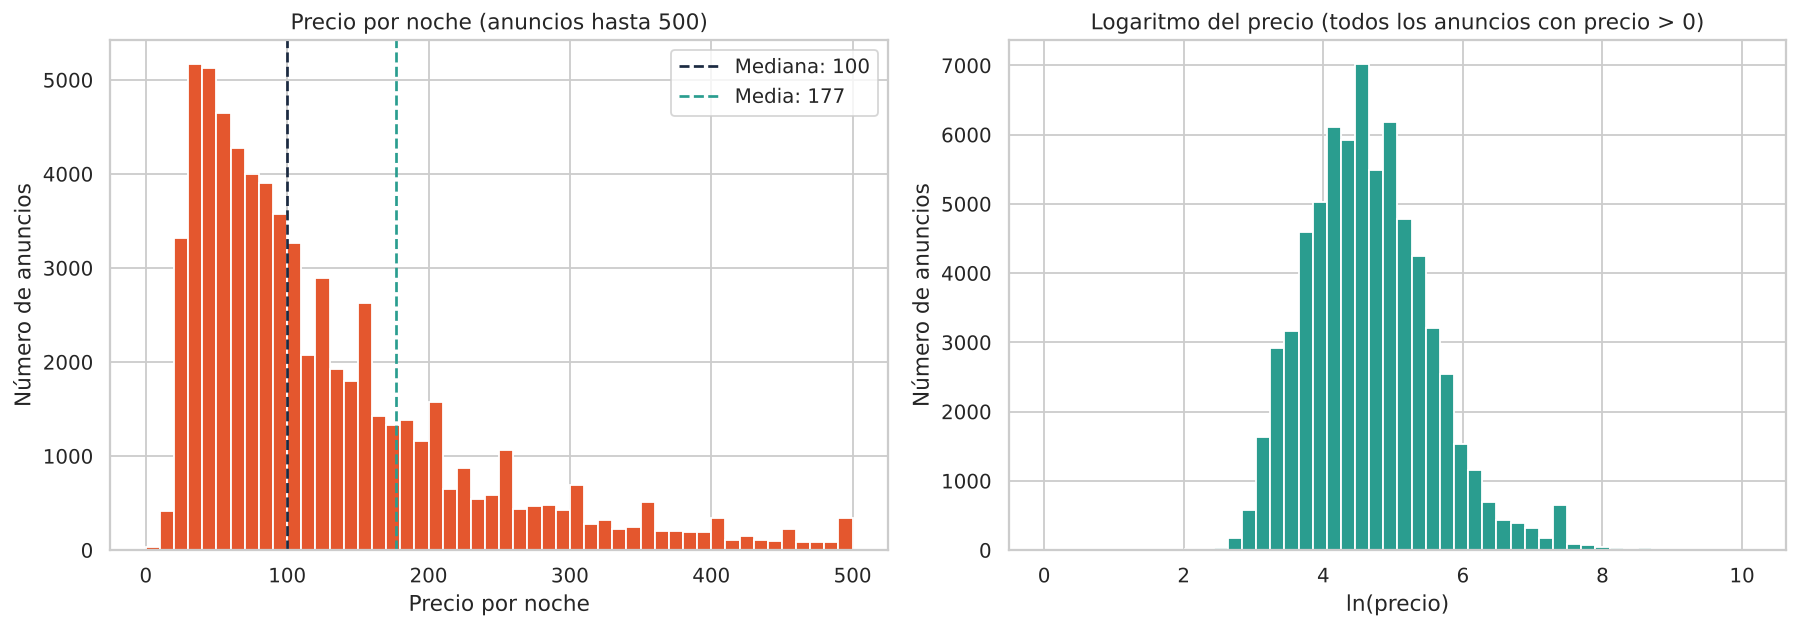

In [12]:
precio = df['price_num'].dropna()
precio_pos = precio[precio > 0]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Histograma hasta 500 para ver la forma principal
ax[0].hist(precio[precio <= 500], bins=50, color=CORAL, edgecolor='white')
ax[0].axvline(precio.median(), color=AZUL, linestyle='--', label=f'Mediana: {precio.median():,.0f}')
ax[0].axvline(precio.mean(), color=VERDE, linestyle='--', label=f'Media: {precio.mean():,.0f}')
ax[0].set_title('Precio por noche (anuncios hasta 500)')
ax[0].set_xlabel('Precio por noche')
ax[0].set_ylabel('Número de anuncios')
ax[0].legend()

# Histograma del logaritmo del precio
ax[1].hist(np.log(precio_pos), bins=50, color=VERDE, edgecolor='white')
ax[1].set_title('Logaritmo del precio (todos los anuncios con precio > 0)')
ax[1].set_xlabel('ln(precio)')
ax[1].set_ylabel('Número de anuncios')

plt.tight_layout()
plt.show()

print('Asimetría del precio:', round(precio.skew(), 2))
print('Asimetría del logaritmo del precio:', round(np.log(precio_pos).skew(), 2))

## **2.8 Análisis univariado de las variables categóricas**

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

# Tipo de alojamiento
orden = df['room_type'].value_counts()
ax[0].bar(orden.index, orden.values, color=AZUL)
for i, v in enumerate(orden.values):
    ax[0].text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=9)
ax[0].set_title('Anuncios por tipo de alojamiento')
ax[0].tick_params(axis='x', rotation=20)

# 10 barrios con más anuncios
barrios = df['neighbourhood_cleansed'].value_counts().head(10).sort_values()
ax[1].barh(barrios.index, barrios.values, color=CORAL)
ax[1].set_title('10 barrios con más anuncios')

# 10 tipos de propiedad más frecuentes
props = df['property_type'].value_counts().head(10).sort_values()
ax[2].barh(props.index, props.values, color=VERDE)
ax[2].set_title('10 tipos de propiedad más frecuentes')

plt.tight_layout()
plt.show()

## **2.9 Análisis bivariado: relación de cada variable con el precio**

Se usa escala logarítmica en el eje del precio porque la distribución tiene una cola muy larga.

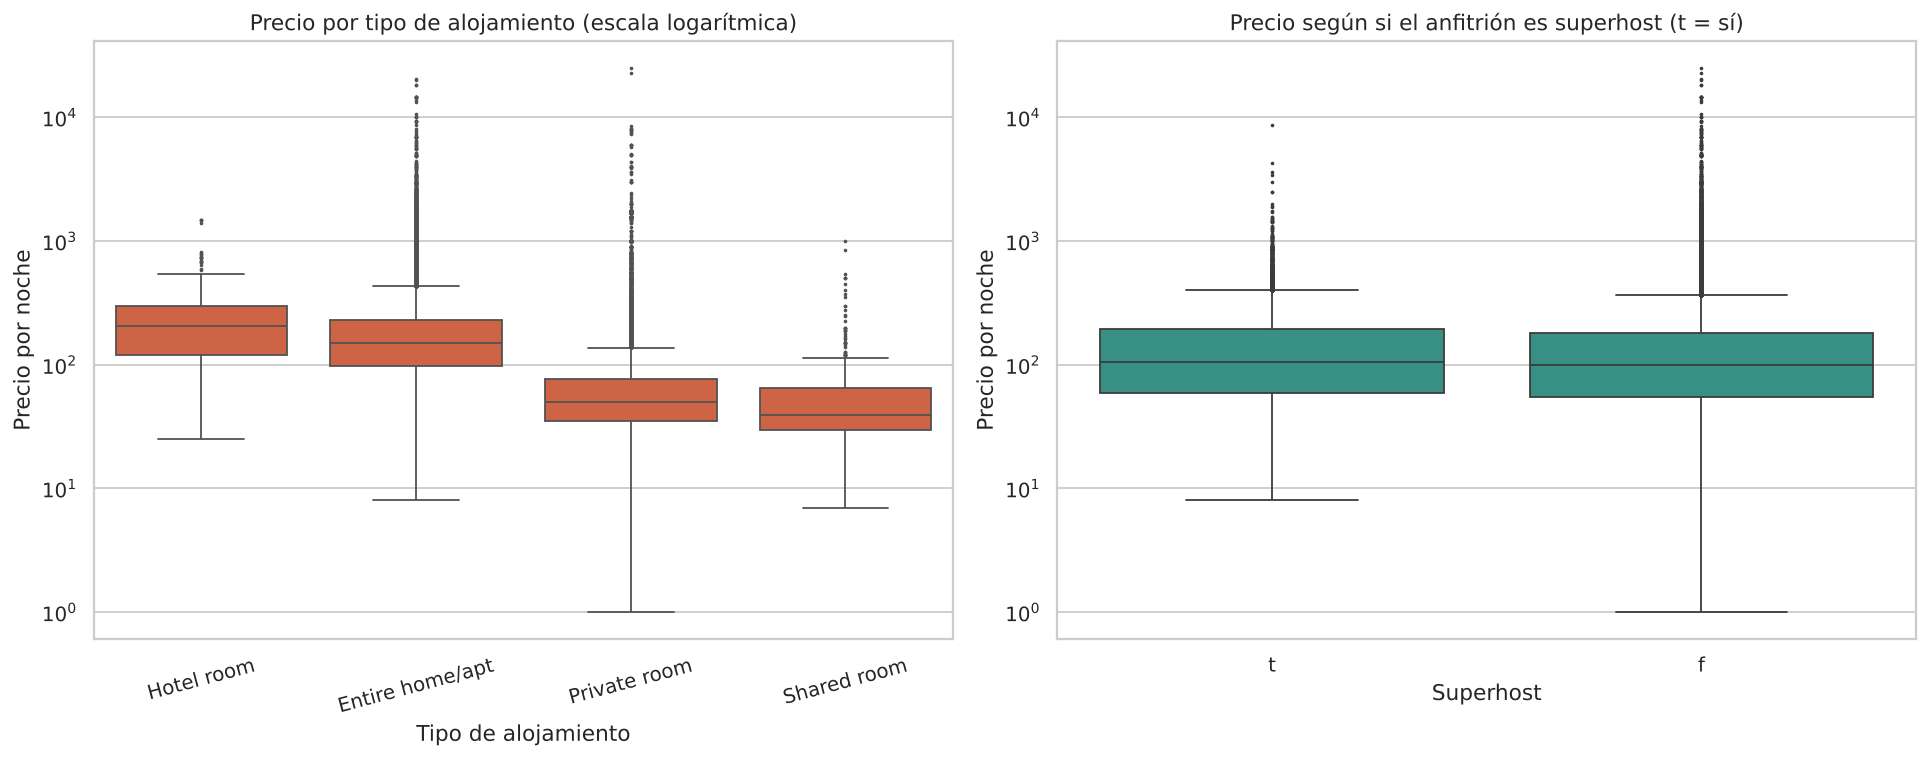

In [14]:
datos = df[df['price_num'] > 0]
orden_tipos = ['Hotel room', 'Entire home/apt', 'Private room', 'Shared room']

fig, ax = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(data=datos, x='room_type', y='price_num', order=orden_tipos, color=CORAL, ax=ax[0], fliersize=1)
ax[0].set_yscale('log')
ax[0].set_title('Precio por tipo de alojamiento (escala logarítmica)')
ax[0].set_xlabel('Tipo de alojamiento')
ax[0].set_ylabel('Precio por noche')
ax[0].tick_params(axis='x', rotation=15)

sns.boxplot(data=datos, x='host_is_superhost', y='price_num', order=['t', 'f'], color=VERDE, ax=ax[1], fliersize=1)
ax[1].set_yscale('log')
ax[1].set_title('Precio según si el anfitrión es superhost (t = sí)')
ax[1].set_xlabel('Superhost')
ax[1].set_ylabel('Precio por noche')

plt.tight_layout()
plt.show()

print(df.groupby('room_type')['price_num'].agg(['count', 'median', 'mean']).round(1))

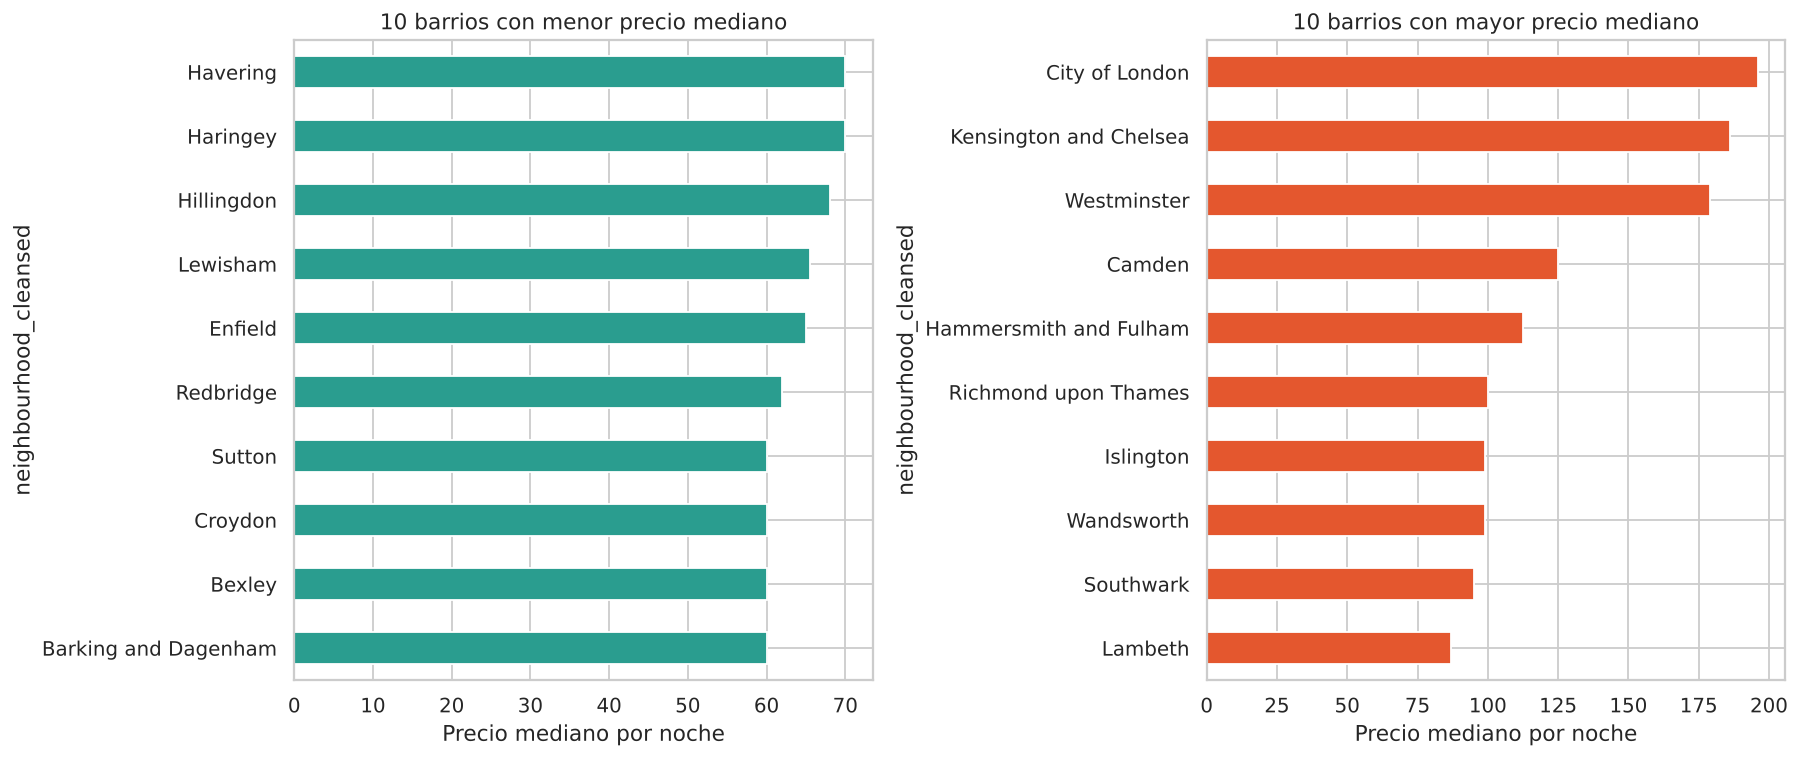

,median,count
neighbourhood_cleansed,,
City of London,196.00,424
Kensington and Chelsea,186.00,4612
Westminster,179.00,7763
Camden,125.00,4707
Hammersmith and Fulham,112.50,2996


In [15]:
# Precio mediano por barrio (solo barrios con al menos 100 anuncios)
por_barrio = df.groupby('neighbourhood_cleansed')['price_num'].agg(['median', 'count'])
por_barrio = por_barrio[por_barrio['count'] >= 100].sort_values('median')

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
por_barrio['median'].head(10).plot(kind='barh', color=VERDE, ax=ax[0])
ax[0].set_title('10 barrios con menor precio mediano')
ax[0].set_xlabel('Precio mediano por noche')
por_barrio['median'].tail(10).plot(kind='barh', color=CORAL, ax=ax[1])
ax[1].set_title('10 barrios con mayor precio mediano')
ax[1].set_xlabel('Precio mediano por noche')
plt.tight_layout()
plt.show()

por_barrio.sort_values('median', ascending=False).head(5)

In [16]:
datos = df[(df['price_num'] > 0) & (df['accommodates'] <= 10)]

fig, ax = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(data=datos, x='accommodates', y='price_num', color=AZUL, ax=ax[0], fliersize=1)
ax[0].set_yscale('log')
ax[0].set_title('Precio según capacidad (huéspedes)')
ax[0].set_xlabel('Capacidad (huéspedes)')
ax[0].set_ylabel('Precio por noche')

dh = df[(df['price_num'] > 0) & (df['bedrooms'] <= 6)]
sns.boxplot(data=dh, x='bedrooms', y='price_num', color=VERDE, ax=ax[1], fliersize=1)
ax[1].set_yscale('log')
ax[1].set_title('Precio según número de habitaciones')
ax[1].set_xlabel('Habitaciones')
ax[1].set_ylabel('Precio por noche')

plt.tight_layout()
plt.show()

## **2.10 Matriz de correlación**

Se calcula la correlación entre las variables numéricas. Valores cercanos a 1 o -1 indican relación fuerte; cercanos a 0, relación débil.

In [17]:
corr = df[vars_num].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', center=0, linewidths=.5, annot_kws={'size': 8})
plt.title('Matriz de correlación (Pearson)')
plt.tight_layout()
plt.show()

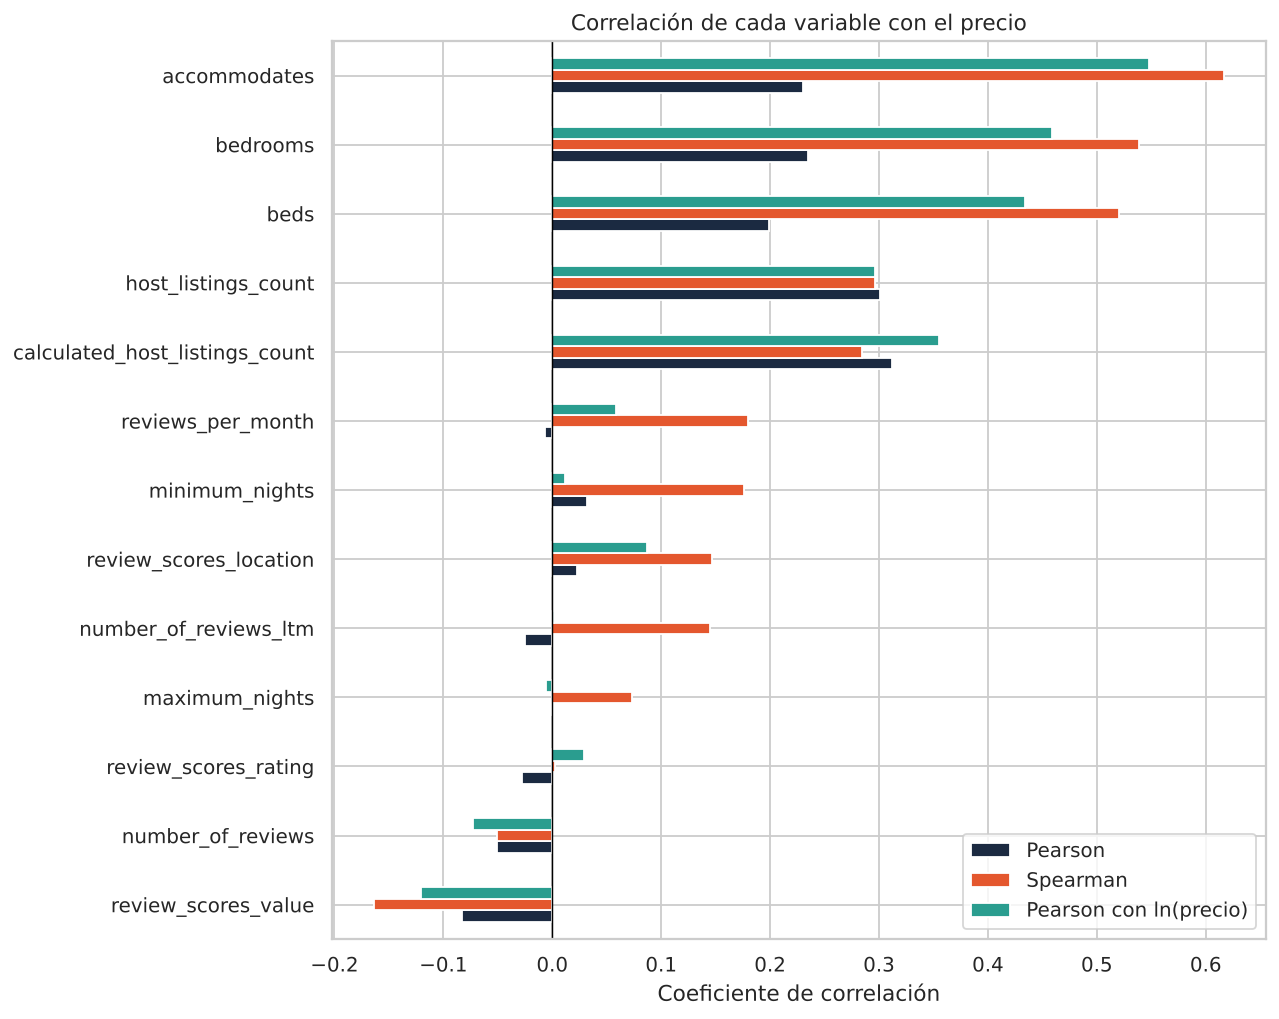

,Pearson,Spearman,Pearson con ln(precio)
accommodates,0.23,0.62,0.55
bedrooms,0.23,0.54,0.46
beds,0.20,0.52,0.43
host_listings_count,0.30,0.30,0.30
calculated_host_listings_count,0.31,0.28,0.35
reviews_per_month,-0.01,0.18,0.06
minimum_nights,0.03,0.18,0.01
review_scores_location,0.02,0.15,0.09
number_of_reviews_ltm,-0.03,0.14,0.00
maximum_nights,-0.00,0.07,-0.01


In [18]:
# Correlación de cada variable con el precio. Spearman es más robusto cuando hay atípicos y asimetría
df['ln_precio'] = np.log(df['price_num'].where(df['price_num'] > 0))
cp = pd.DataFrame({
    'Pearson': df[vars_num].corr()['price_num'],
    'Spearman': df[vars_num].corr(method='spearman')['price_num'],
    'Pearson con ln(precio)': df[vars_num].corrwith(df['ln_precio'])
}).drop('price_num').sort_values('Spearman')

cp.plot(kind='barh', figsize=(10, 8), color=[AZUL, CORAL, VERDE])
plt.title('Correlación de cada variable con el precio')
plt.xlabel('Coeficiente de correlación')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

cp.round(2).sort_values('Spearman', ascending=False)

## **2.11 Valores atípicos (outliers)**

Se usa el criterio del rango intercuartílico (IQR): se consideran atípicos los valores por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR.

In [19]:
resumen_atipicos = []
for col in vars_num:
    serie = df[col].dropna()
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_atip = ((serie < lim_inf) | (serie > lim_sup)).sum()
    resumen_atipicos.append({
        'Variable': col, 'Q1': round(q1, 2), 'Q3': round(q3, 2), 'IQR': round(iqr, 2),
        'Límite inferior': round(lim_inf, 2), 'Límite superior': round(lim_sup, 2),
        'Total atípicos': n_atip, '% atípicos': round(n_atip / len(serie) * 100, 2)
    })

df_atipicos = pd.DataFrame(resumen_atipicos).sort_values('Total atípicos', ascending=False)
df_atipicos

,Variable,Q1,Q3,IQR,Límite inferior,Límite superior,Total atípicos,% atípicos
13,calculated_host_listings_count,1.00,4.00,3.00,-3.50,8.50,11908,17.17
12,host_listings_count,1.00,5.00,4.00,-5.00,11.00,11127,16.05
6,number_of_reviews,1.00,16.00,15.00,-21.50,38.50,8318,12.00
7,number_of_reviews_ltm,0.00,5.00,5.00,-7.50,12.50,7980,11.51
4,minimum_nights,1.00,4.00,3.00,-3.50,8.50,6031,8.70
3,beds,1.00,2.00,1.00,-0.50,3.50,5672,8.32
0,price_num,55.00,180.00,125.00,-132.50,367.50,5441,7.85
11,reviews_per_month,0.12,1.08,0.96,-1.32,2.52,4529,8.62
9,review_scores_location,4.67,5.00,0.33,4.18,5.50,3763,7.31
8,review_scores_rating,4.50,5.00,0.50,3.75,5.75,3089,5.88


Anuncios con precio mayor a 1.000: 1303
Anuncios con precio mayor a 5.000: 65

maximum_nights mayor a 1.125 noches (valor imposible): 9
Valor máximo de maximum_nights: 524,855,552
Anuncios con capacidad (accommodates) igual a 0: 5


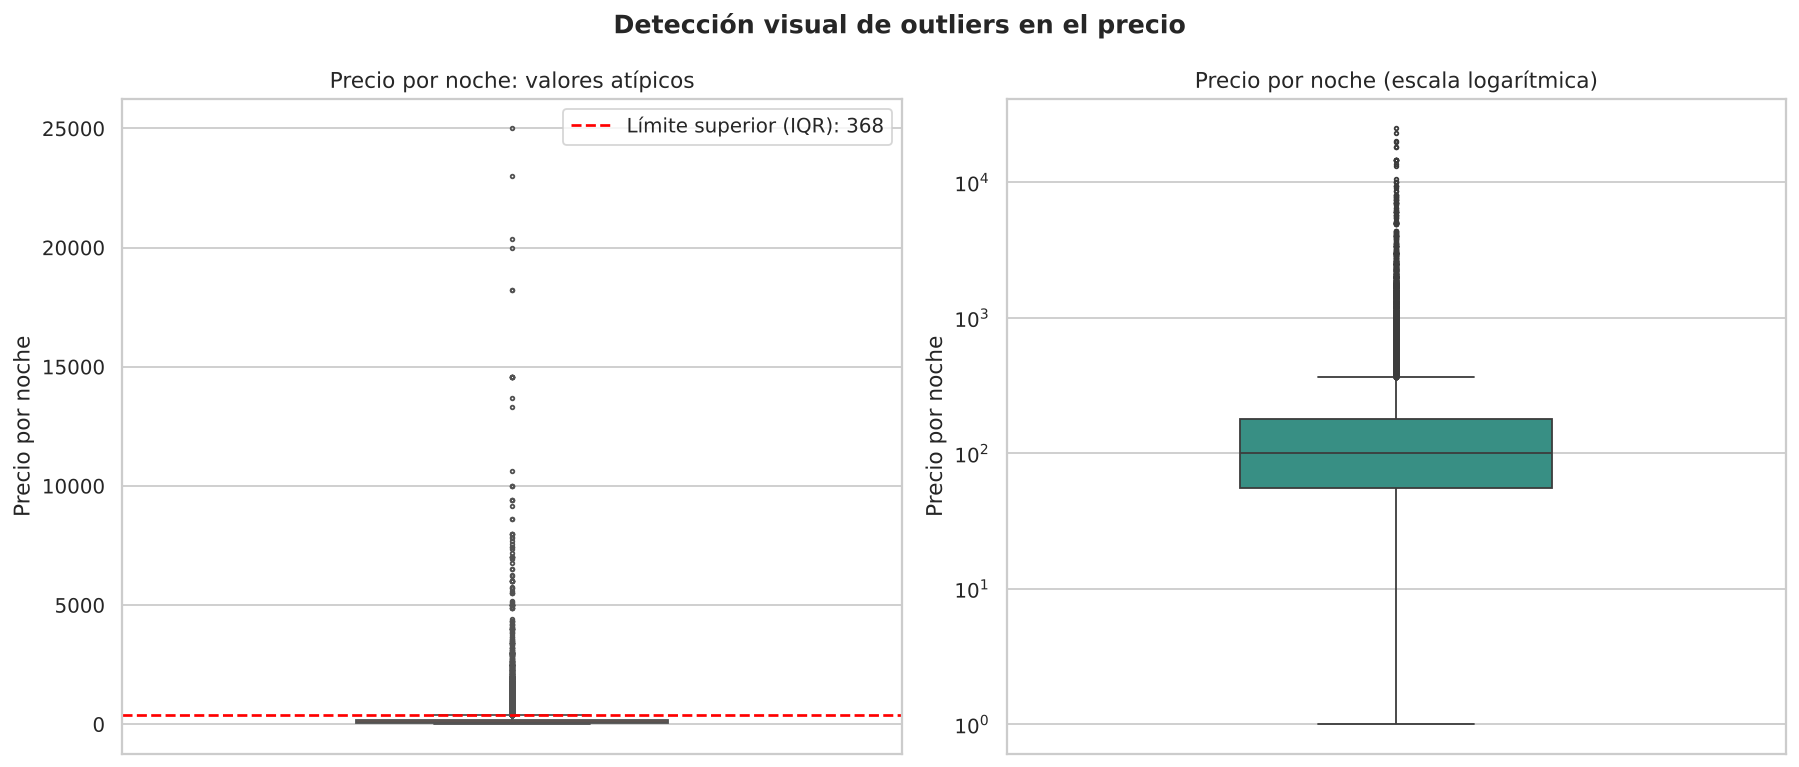

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

q1, q3 = precio.quantile(0.25), precio.quantile(0.75)
lim_sup = q3 + 1.5 * (q3 - q1)

sns.boxplot(y=precio, ax=ax[0], color=CORAL, width=0.4, fliersize=2)
ax[0].axhline(lim_sup, color='red', linestyle='--', label=f'Límite superior (IQR): {lim_sup:,.0f}')
ax[0].set_title('Precio por noche: valores atípicos')
ax[0].set_ylabel('Precio por noche')
ax[0].legend()

sns.boxplot(y=precio_pos, ax=ax[1], color=VERDE, width=0.4, fliersize=2)
ax[1].set_yscale('log')
ax[1].set_title('Precio por noche (escala logarítmica)')
ax[1].set_ylabel('Precio por noche')

plt.suptitle('Detección visual de outliers en el precio', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Anuncios con precio mayor a 1.000:', (precio > 1000).sum())
print('Anuncios con precio mayor a 5.000:', (precio > 5000).sum())

# Otras inconsistencias detectadas en variables numéricas
print('\nmaximum_nights mayor a 1.125 noches (valor imposible):', (df['maximum_nights'] > 1125).sum())
print('Valor máximo de maximum_nights:', f"{df['maximum_nights'].max():,.0f}")
print('Anuncios con capacidad (accommodates) igual a 0:', (df['accommodates'] == 0).sum())
print('Anuncios con minimum_nights mayor a 365:', (df['minimum_nights'] > 365).sum())

## **2.12 Distribución geográfica del precio**

In [21]:
datos_mapa = df[df['price_num'] > 0]
muestra = datos_mapa.sample(min(30000, len(datos_mapa)), random_state=42)

plt.figure(figsize=(10, 7))
sc = plt.scatter(muestra['longitude'], muestra['latitude'], c=np.log(muestra['price_num']),
                 cmap='plasma', s=3, alpha=0.6, vmin=3, vmax=7)
plt.colorbar(sc, label='ln(precio por noche)')
plt.title('Ubicación de los anuncios y nivel de precio (muestra de 30.000)')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.tight_layout()
plt.show()

## **2.13 Hallazgos de la Fase 2**

**Tamaño y calidad general.** El conjunto tiene 69.351 anuncios y 52 variables (27 numéricas, 3 de fecha y 22 de texto o categóricas). No hay filas duplicadas y cada `id` es único. 7 registros no tienen precio y 19 tienen precio igual a 0 (13 habitaciones de hotel y 6 habitaciones privadas), que habrá que tratar como datos no válidos.

**Variable objetivo.** El precio mediano es 100 y el medio 177, con desviación estándar de 413 (CV ≈ 233 %) y asimetría de 22,2: la distribución tiene una cola muy larga hacia precios altos. Al aplicar logaritmo, la asimetría baja a 0,67 y la forma se parece a una campana, por lo que conviene modelar `ln(precio)`.

**Tipo de alojamiento y ubicación.** El 59,4 % son casas completas y el 39,6 % habitaciones privadas. Las medianas son 202 (hotel), 149 (casa completa), 50 (habitación privada) y 39 (compartida). Los barrios con mayor precio mediano son City of London (196), Kensington and Chelsea (186) y Westminster (179); Westminster es además el barrio con más anuncios (7.763). El mapa muestra el precio más alto concentrado en el centro.

**Correlaciones.** Con el precio sin transformar, la correlación de Pearson es baja (0,23 con la capacidad), pero con Spearman sube a 0,62 y con ln(precio) a 0,55: la relación es fuerte pero no lineal y los atípicos la distorsionan. Capacidad, habitaciones y camas están muy relacionadas entre sí (0,75 a 0,83), lo que sugiere multicolinealidad. Las puntuaciones de reseñas casi no se relacionan con el precio (|r| < 0,1). Los anfitriones con muchos anuncios tienden a cobrar más (r ≈ 0,30).

**Datos faltantes.** 48 de las 52 columnas tienen algún nulo. Las más afectadas son `host_about` (46,7 %), `neighborhood_overview` (42,4 %) y las de respuesta del anfitrión (38,3 %). Las puntuaciones de reseñas faltan en cerca del 24 al 26 % de los anuncios, que corresponden a alojamientos sin reseñas. `bedrooms` tiene 5,0 % de nulos y `beds` 1,7 %.

**Valores atípicos.** Con el criterio IQR, 5.441 anuncios (7,9 %) superan los 367,5 de precio; 1.303 superan los 1.000 y 65 los 5.000. Además hay inconsistencias: `maximum_nights` llega a 524.855.552 (9 anuncios superan el máximo posible de 1.125), 5 anuncios tienen capacidad 0 y 33 exigen más de 365 noches mínimas.

**Implicaciones para la Fase 3 (preparación de los datos).** Trabajar con `ln(precio)`; excluir los 7 registros sin precio y los 19 con precio 0; decidir cómo tratar los precios extremos; imputar `bedrooms` y `beds`; crear un indicador de «sin reseñas» en vez de imputar puntuaciones; corregir o descartar `maximum_nights`; derivar variables (número de comodidades, antigüedad del anfitrión, distancia al centro); codificar variables categóricas y prescindir de columnas de texto libre y de enlaces.

# **FASE 3: PREPARACIÓN DE LOS DATOS**

En esta fase se construye, a partir de los datos originales, el conjunto que usarán los modelos. Cada decisión responde a un hallazgo de la Fase 2:

| Hallazgo de la Fase 2 | Decisión en la Fase 3 |
|---|---|
| 7 anuncios sin precio y 19 con precio igual a 0 | Se excluyen del análisis |
| 5 anuncios con capacidad igual a 0 | Ya quedan excluidos junto con los precios no válidos (se verifica) |
| `maximum_nights` y `minimum_nights` con valores imposibles | Se limitan a 1.125 y 365 noches |
| Precio con cola larga y valores extremos | Se modela ln(precio) y se excluyen los extremos según el criterio IQR sobre el logaritmo |
| Datos faltantes en habitaciones, camas y baños | Se imputan con la mediana por tipo de alojamiento y capacidad |
| Anuncios sin reseñas | Se crea un indicador `sin_resenas` y se rellenan las puntuaciones con la mediana |
| Columnas con muchos nulos, textos libres y enlaces | Se descartan o se transforman en variables numéricas |
| Capacidad, habitaciones y camas muy correlacionadas | Se descarta la variable redundante |
| Variables categóricas | Se codifican con variables indicadoras (one-hot) |
| Variables con escalas distintas | Se estandarizan; el escalador se ajusta solo con los datos de entrenamiento |

## **3.1 Exclusión de registros no válidos**

Se trabaja sobre una copia (`dfp`) para no alterar los datos originales. Cada paso queda registrado en una tabla para poder auditar cuántos anuncios se excluyen y por qué.

In [22]:
dfp = df.copy()   # copia de trabajo
registro = [('Datos originales', 0, len(dfp))]

def excluir(d, conservar, etiqueta):
    # Conserva las filas que cumplen la condición y deja constancia de cuántas se excluyen
    antes = len(d)
    d = d[conservar(d)]
    registro.append((etiqueta, antes - len(d), len(d)))
    return d

dfp = excluir(dfp, lambda d: d['price_num'].notna(), 'Anuncios sin precio')
dfp = excluir(dfp, lambda d: d['price_num'] > 0, 'Anuncios con precio igual a 0')

print('Anuncios con capacidad igual a 0 que quedan:', (dfp['accommodates'] == 0).sum())

pd.DataFrame(registro, columns=['Paso', 'Registros excluidos', 'Registros restantes'])

Anuncios con capacidad igual a 0 que quedan: 0


,Paso,Registros excluidos,Registros restantes
0,Datos originales,0,69351
1,Anuncios sin precio,7,69344
2,Anuncios con precio igual a 0,19,69325


## **3.2 Corrección de inconsistencias**

Airbnb no permite más de 1.125 noches máximas por reserva; los valores superiores son errores. Las estancias mínimas de más de un año tampoco son razonables. En lugar de eliminar esos anuncios, se limitan los valores.

In [23]:
print('Anuncios con maximum_nights > 1.125:', (dfp['maximum_nights'] > 1125).sum())
print('Anuncios con minimum_nights > 365:', (dfp['minimum_nights'] > 365).sum())

dfp['maximum_nights'] = dfp['maximum_nights'].clip(upper=1125)
dfp['minimum_nights'] = dfp['minimum_nights'].clip(upper=365)

print('\nMáximo de maximum_nights después:', dfp['maximum_nights'].max())
print('Máximo de minimum_nights después:', dfp['minimum_nights'].max())

Anuncios con maximum_nights > 1.125: 9
Anuncios con minimum_nights > 365: 33

Máximo de maximum_nights después: 1125.0


## **3.3 Tratamiento de los precios extremos**

Como se modelará el logaritmo del precio, el criterio IQR se aplica sobre `ln(precio)`: es más estricto con los precios bajos y menos agresivo con los altos que aplicarlo sobre el precio sin transformar (que habría excluido 5.441 anuncios).

In [24]:
dfp['ln_precio'] = np.log(dfp['price_num'])
antes = dfp.copy()   # copia para comparar antes y después

q1, q3 = dfp['ln_precio'].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f'Límites sobre ln(precio): {lim_inf:.2f} a {lim_sup:.2f}')
print(f'Equivalen a un precio por noche entre {np.exp(lim_inf):,.1f} y {np.exp(lim_sup):,.1f}')
print('Anuncios por debajo del límite inferior:', (dfp['ln_precio'] < lim_inf).sum())
print('Anuncios por encima del límite superior:', (dfp['ln_precio'] > lim_sup).sum())

dfp = dfp[dfp['ln_precio'].between(lim_inf, lim_sup)]
registro.append(('Precios atípicos (IQR sobre ln precio)', len(antes) - len(dfp), len(dfp)))

print('\nAsimetría del precio antes:', round(antes['price_num'].skew(), 2), '| después:', round(dfp['price_num'].skew(), 2))
print('Precio máximo antes:', f"{antes['price_num'].max():,.0f}", '| después:', f"{dfp['price_num'].max():,.0f}")
print('Registros restantes:', len(dfp))

Límites sobre ln(precio): 2.23 a 6.97
Equivalen a un precio por noche entre 9.3 y 1,065.7
Anuncios por debajo del límite inferior: 13
Anuncios por encima del límite superior: 1244

Asimetría del precio antes: 22.18 | después: 2.82
Precio máximo antes: 25,000 | después: 1,064


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

ax[0].hist(antes['price_num'].clip(upper=1500), bins=60, color=CORAL, edgecolor='white')
ax[0].set_title('Antes (los precios sobre 1.500 se agrupan en el último valor)')
ax[0].set_xlabel('Precio por noche')
ax[0].set_ylabel('Número de anuncios')

ax[1].hist(dfp['price_num'], bins=60, color=VERDE, edgecolor='white')
ax[1].set_title('Después de excluir los precios atípicos')
ax[1].set_xlabel('Precio por noche')

plt.tight_layout()
plt.show()

## **3.4 Tratamiento de los datos faltantes**

Se revisan primero las columnas que se usarán en el modelo y luego se aplica una estrategia distinta según el tipo de variable.

In [26]:
cols_rev = ['bedrooms', 'beds', 'bathrooms_text', 'review_scores_rating', 'review_scores_location',
            'review_scores_value', 'reviews_per_month', 'host_is_superhost', 'host_identity_verified',
            'instant_bookable', 'host_since', 'host_listings_count', 'calculated_host_listings_count']
nulos_antes = dfp[cols_rev].isnull().sum()
nulos_antes[nulos_antes > 0].to_frame('Nulos antes')

,Nulos antes
bedrooms,3326
beds,1180
bathrooms_text,114
review_scores_rating,16051
review_scores_location,17086
review_scores_value,17089
reviews_per_month,16051
host_is_superhost,1
host_identity_verified,5
host_since,5


In [27]:
# a) Baños: se extrae el número del texto (por ejemplo '1.5 shared baths' -> 1.5)
txt = dfp['bathrooms_text'].str.lower()
dfp['banos'] = txt.str.extract(r'(\d+\.?\d*)')[0].astype(float)
dfp.loc[txt.str.contains('half', na=False) & dfp['banos'].isna(), 'banos'] = 0.5
dfp['bano_compartido'] = txt.str.contains('shared', na=False).astype(int)

# b) Habitaciones, camas y baños: mediana del grupo (tipo de alojamiento y capacidad);
#    si el grupo no tiene ningún dato, se usa la mediana general
for col in ['bedrooms', 'beds', 'banos']:
    mediana_grupo = dfp.groupby(['room_type', 'accommodates'])[col].transform('median')
    dfp[col] = dfp[col].fillna(mediana_grupo).fillna(dfp[col].median())

# b2) Valores extremos de habitaciones, camas y baños (errores de captura): se limitan al percentil 99,9
for col in ['bedrooms', 'beds', 'banos']:
    limite = dfp[col].quantile(0.999)
    print(f'{col}: máximo antes {dfp[col].max():.0f} | límite (percentil 99,9) {limite:.1f}')
    dfp[col] = dfp[col].clip(upper=limite)

# c) Reseñas: el indicador conserva la información de que el anuncio no tiene reseñas
dfp['sin_resenas'] = dfp['review_scores_rating'].isna().astype(int)
for col in ['review_scores_rating', 'review_scores_location', 'review_scores_value']:
    dfp[col] = dfp[col].fillna(dfp[col].median())
dfp['reviews_per_month'] = dfp['reviews_per_month'].fillna(0)

# d) Conteos de anuncios del anfitrión con algún dato faltante: mediana
for col in ['host_listings_count', 'host_total_listings_count', 'calculated_host_listings_count']:
    dfp[col] = dfp[col].fillna(dfp[col].median())

# e) Variables t/f del anfitrión: se rellenan con la moda
for col in ['host_is_superhost', 'host_identity_verified', 'instant_bookable']:
    dfp[col] = dfp[col].fillna(dfp[col].mode()[0])

cols_check = ['bedrooms', 'beds', 'banos', 'host_listings_count', 'host_total_listings_count', 'calculated_host_listings_count', 'review_scores_rating', 'review_scores_location',
              'review_scores_value', 'reviews_per_month', 'host_is_superhost',
              'host_identity_verified', 'instant_bookable']
print('Nulos restantes en las variables tratadas:', int(dfp[cols_check].isnull().sum().sum()))
print('Anuncios sin reseñas:', dfp['sin_resenas'].sum(), f"({dfp['sin_resenas'].mean() * 100:.1f} %)")
dfp[['bedrooms', 'beds', 'banos']].describe().T.round(2)

bedrooms: máximo antes 50 | límite (percentil 99,9) 6.0
beds: máximo antes 38 | límite (percentil 99,9) 10.0
banos: máximo antes 40 | límite (percentil 99,9) 5.0
Nulos restantes en las variables tratadas: 0
Anuncios sin reseñas: 16051 (23.6 %)


,count,mean,std,min,25%,50%,75%,max
bedrooms,"68,068.00",1.47,0.83,1.00,1.00,1.00,2.00,6.00
beds,"68,068.00",1.74,1.17,1.00,1.00,1.00,2.00,10.00
banos,"68,068.00",1.30,0.56,0.00,1.00,1.00,1.50,5.00


## **3.5 Creación de variables (ingeniería de características)**

A partir de las columnas originales se construyen variables que describen mejor al alojamiento y a su anfitrión:

* `antiguedad_anfitrion`: años transcurridos desde que el anfitrión se registró.
* `n_amenities`: número de comodidades del anuncio (la columna original es una lista escrita como texto).
* `dist_centro_km`: distancia en kilómetros al centro de Londres (Charing Cross), calculada con la fórmula de Haversine a partir de la latitud y la longitud.
* `banos` y `bano_compartido`: número de baños y si es compartido (ya creadas en el paso anterior).
* Las variables `t`/`f` se convierten en 1/0.

In [28]:
import json

# a) Antigüedad del anfitrión (años) respecto a la fecha de captura de los datos
FECHA_REF = df['last_review'].max()
dfp['antiguedad_anfitrion'] = (FECHA_REF - dfp['host_since']).dt.days / 365.25
dfp['antiguedad_anfitrion'] = dfp['antiguedad_anfitrion'].fillna(dfp['antiguedad_anfitrion'].median())

# b) Número de comodidades
dfp['n_amenities'] = dfp['amenities'].fillna('[]').apply(lambda x: len(json.loads(x)))

# c) Distancia al centro de Londres (Charing Cross: 51.5074, -0.1278) con la fórmula de Haversine
def haversine(lat1, lon1, lat2, lon2):
    R = 6371   # radio de la Tierra en km
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

dfp['dist_centro_km'] = haversine(dfp['latitude'], dfp['longitude'], 51.5074, -0.1278)

# d) Variables t/f a 1/0
for col in ['host_is_superhost', 'host_identity_verified', 'instant_bookable']:
    dfp[col] = (dfp[col] == 't').astype(int)

dfp[['antiguedad_anfitrion', 'n_amenities', 'dist_centro_km', 'banos']].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
antiguedad_anfitrion,"68,068.00",6.16,2.81,0.01,4.23,6.55,8.14,13.77
n_amenities,"68,068.00",23.09,12.56,0.00,13.00,21.00,31.00,90.00
dist_centro_km,"68,068.00",7.50,4.80,0.03,4.19,6.22,9.75,30.45
banos,"68,068.00",1.30,0.56,0.00,1.00,1.00,1.50,5.00


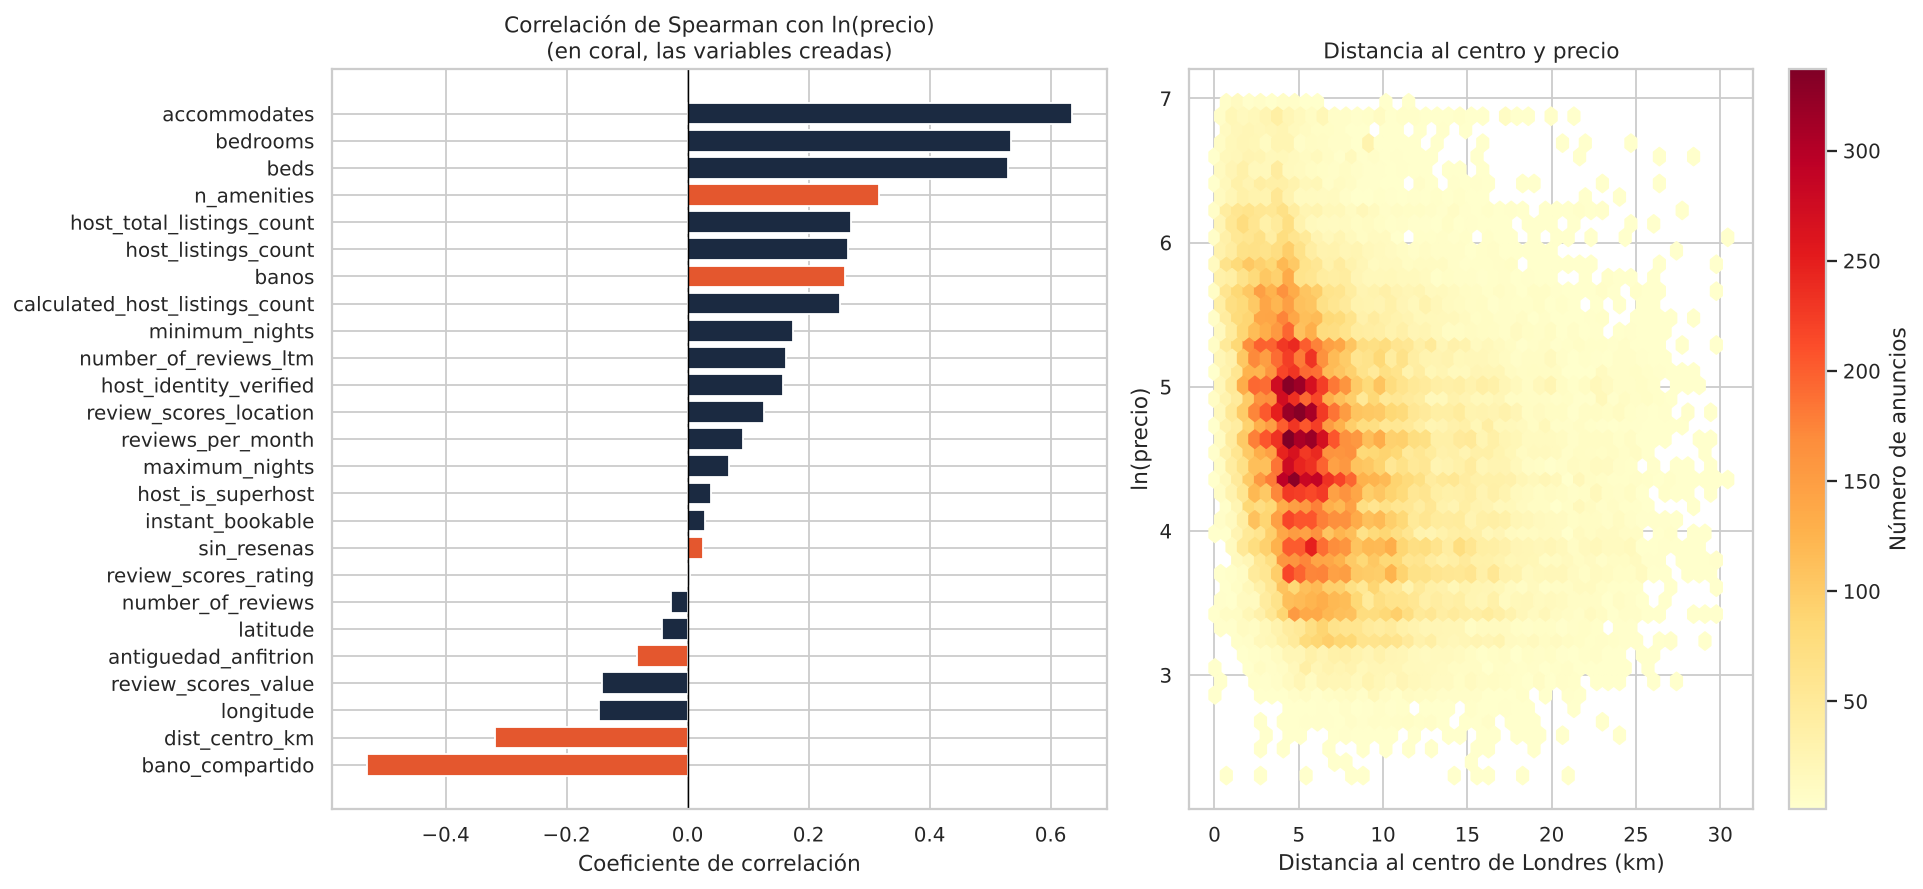

accommodates                     0.64
bedrooms                         0.53
beds                             0.53
n_amenities                      0.32
host_total_listings_count        0.27
host_listings_count              0.26
banos                            0.26
calculated_host_listings_count   0.25

In [29]:
num_feats = ['accommodates', 'bedrooms', 'beds', 'banos', 'bano_compartido', 'minimum_nights', 'maximum_nights',
             'number_of_reviews', 'number_of_reviews_ltm', 'reviews_per_month', 'review_scores_rating',
             'review_scores_location', 'review_scores_value', 'sin_resenas', 'host_listings_count',
             'host_total_listings_count', 'calculated_host_listings_count', 'host_is_superhost',
             'host_identity_verified', 'instant_bookable', 'antiguedad_anfitrion', 'n_amenities',
             'dist_centro_km', 'latitude', 'longitude']
nuevas = ['banos', 'bano_compartido', 'sin_resenas', 'antiguedad_anfitrion', 'n_amenities', 'dist_centro_km']

corr_ln = dfp[num_feats + ['ln_precio']].corr(method='spearman')['ln_precio'].drop('ln_precio').sort_values()

fig, ax = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1.1, 1]})
colores = [CORAL if v in nuevas else AZUL for v in corr_ln.index]
ax[0].barh(corr_ln.index, corr_ln.values, color=colores)
ax[0].axvline(0, color='black', linewidth=0.8)
ax[0].set_title('Correlación de Spearman con ln(precio)\n(en coral, las variables creadas)')
ax[0].set_xlabel('Coeficiente de correlación')

hb = ax[1].hexbin(dfp['dist_centro_km'], dfp['ln_precio'], gridsize=45, cmap='YlOrRd', mincnt=1)
plt.colorbar(hb, ax=ax[1], label='Número de anuncios')
ax[1].set_title('Distancia al centro y precio')
ax[1].set_xlabel('Distancia al centro de Londres (km)')
ax[1].set_ylabel('ln(precio)')

plt.tight_layout()
plt.show()

corr_ln.sort_values(ascending=False).head(8).round(2)

## **3.6 Selección de variables y multicolinealidad**

Cuando dos variables numéricas tienen una correlación mayor que 0,80 aportan casi la misma información. Se listan esos pares y se conserva solo una variable de cada uno.

In [30]:
corr_abs = dfp[num_feats].corr().abs()
pares = []
for i, a in enumerate(num_feats):
    for b in num_feats[i + 1:]:
        if corr_abs.loc[a, b] > 0.80:
            pares.append((a, b, round(corr_abs.loc[a, b], 2)))

pd.DataFrame(pares, columns=['Variable A', 'Variable B', '|Correlación|']).sort_values('|Correlación|', ascending=False)

,Variable A,Variable B,|Correlación|
1,accommodates,beds,0.84
0,accommodates,bedrooms,0.82
2,host_listings_count,host_total_listings_count,0.80


Se descartan `beds` (correlación de 0,84 con la capacidad) y `host_total_listings_count` (0,80 con `host_listings_count`). La capacidad se conserva porque es la variable con mayor relación con el precio. `bedrooms` también está correlacionada con la capacidad (0,82), pero se conserva porque aporta información propia sobre la distribución del espacio; su efecto se revisará en el modelado.

In [31]:
descartar = ['beds', 'host_total_listings_count']
num_cols = [c for c in num_feats if c not in descartar]
print('Variables numéricas conservadas:', len(num_cols))
print('Variables numéricas descartadas:', descartar)

Variables numéricas conservadas: 23


## **3.7 Codificación de las variables categóricas**

Los modelos necesitan números. Los tipos de propiedad que representan menos del 1 % de los anuncios se agrupan en «Otros» para no generar decenas de columnas casi vacías, y después las tres variables categóricas se convierten en variables indicadoras (one-hot). Se elimina una categoría de cada variable (`drop_first=True`) para evitar redundancia.

In [32]:
# Agrupar tipos de propiedad poco frecuentes
frec = dfp['property_type'].value_counts(normalize=True)
principales = frec[frec >= 0.01].index
dfp['property_type_agr'] = dfp['property_type'].where(dfp['property_type'].isin(principales), 'Otros')
print('Tipos de propiedad:', dfp['property_type'].nunique(), '->', dfp['property_type_agr'].nunique())

cat_cols = ['room_type', 'property_type_agr', 'neighbourhood_cleansed']
dummies = pd.get_dummies(dfp[cat_cols], drop_first=True, dtype=int)
X = pd.concat([dfp[num_cols], dummies], axis=1)
y = dfp['ln_precio']

print('\nVariables numéricas:', len(num_cols), '| Variables indicadoras:', dummies.shape[1])
print('Variables explicativas en total:', X.shape[1], '| Registros:', X.shape[0])
print('Nulos en X:', X.isnull().sum().sum(), '| Nulos en y:', y.isnull().sum())

Tipos de propiedad: 100 -> 10

Variables numéricas: 23 | Variables indicadoras: 44
Variables explicativas en total: 67 | Registros: 68068


## **3.8 Partición de los datos y escalado**

Se reserva el 20 % de los anuncios como conjunto de prueba, que no se usará hasta la evaluación final. La estandarización (media 0 y desviación 1) se ajusta **solo con el conjunto de entrenamiento** y luego se aplica al de prueba; si se ajustara con todos los datos, la información de la prueba se «filtraría» al modelo. Solo se escalan las variables continuas, no las indicadoras ni las binarias.

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

continuas = [c for c in num_cols if X[c].nunique() > 2]    # excluye las variables binarias
escalador = StandardScaler().fit(X_train[continuas])        # se ajusta solo con entrenamiento

X_train_esc, X_test_esc = X_train.copy(), X_test.copy()
X_train_esc[continuas] = escalador.transform(X_train[continuas])
X_test_esc[continuas] = escalador.transform(X_test[continuas])

print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)
print('Variables escaladas:', len(continuas))
print('\nComprobación en entrenamiento (media y desviación de las variables escaladas):')
X_train_esc[continuas].agg(['mean', 'std']).T.round(2).head(8)

Entrenamiento: (54454, 67) | Prueba: (13614, 67)
Variables escaladas: 18

Comprobación en entrenamiento (media y desviación de las variables escaladas):


,mean,std
accommodates,0.00,1.00
bedrooms,0.00,1.00
banos,0.00,1.00
minimum_nights,-0.00,1.00
maximum_nights,-0.00,1.00
number_of_reviews,-0.00,1.00
number_of_reviews_ltm,-0.00,1.00
reviews_per_month,-0.00,1.00


## **3.9 Conjunto final y resumen de la preparación**

In [34]:
resumen_f3 = pd.DataFrame({
    'Indicador': ['Registros', 'Columnas', 'Valores nulos', 'Asimetría del precio', 'Precio máximo', 'Precio mediano'],
    'Antes (datos originales)': [len(df), original.shape[1], int(original.isnull().sum().sum()),
                                 round(df['price_num'].skew(), 2), f"{df['price_num'].max():,.0f}", f"{df['price_num'].median():,.0f}"],
    'Después (conjunto final)': [len(X), X.shape[1], int(X.isnull().sum().sum()),
                                 round(dfp['price_num'].skew(), 2), f"{dfp['price_num'].max():,.0f}", f"{dfp['price_num'].median():,.0f}"]
})
resumen_f3

,Indicador,Antes (datos originales),Después (conjunto final)
0,Registros,69351,68068
1,Columnas,52,67
2,Valores nulos,332106,0
3,Asimetría del precio,22.18,2.82
4,Precio máximo,"25,000","1,064"
5,Precio mediano,100,99


In [35]:
# Se guarda el conjunto preparado para usarlo en la Fase 4 (modelado)
final = X.copy()
final['ln_precio'] = y
final['price_num'] = dfp['price_num']
final.to_csv('airbnb_londres_preparado.csv', index=False)
print('Archivo guardado: airbnb_londres_preparado.csv', final.shape)

# Descarga opcional al computador (solo funciona en Google Colab)
try:
    from google.colab import files
    files.download('airbnb_londres_preparado.csv')
except ImportError:
    pass

Archivo guardado: airbnb_londres_preparado.csv (68068, 69)


## **3.10 Hallazgos de la Fase 3**

**Registros.** Se excluyeron 1.283 anuncios (1,9 %): 7 sin precio, 19 con precio igual a 0 y 1.257 con precio atípico según el criterio IQR sobre ln(precio), que corresponden a precios por noche menores de 9,3 o mayores de 1.065,7. Los 5 anuncios con capacidad 0 ya estaban entre los de precio igual a 0. Quedan 68.068 anuncios.

**Variable objetivo.** El precio máximo pasó de 25.000 a 1.064 y la asimetría del precio de 22,2 a 2,8. La asimetría de ln(precio) es de 0,25, por lo que el modelo trabajará con esa variable. El precio mediano casi no cambió (de 100 a 99), lo que indica que la exclusión afectó sobre todo a los extremos.

**Datos faltantes.** Se imputaron 3.326 habitaciones, 1.180 camas y 114 baños con la mediana por tipo de alojamiento y capacidad. Los 16.051 anuncios sin reseñas (23,6 %) quedaron marcados con el indicador `sin_resenas`. El conjunto final no tiene valores nulos.

**Variables creadas.** `n_amenities` (mediana de 21 comodidades), `dist_centro_km` (mediana de 6,2 km al centro), `banos` y `bano_compartido` (23,1 % de los anuncios), `antiguedad_anfitrion` (promedio de 6,2 años) y `sin_resenas`. Con ln(precio), la correlación de Spearman es 0,64 para la capacidad, −0,53 para el baño compartido, 0,32 para el número de comodidades, −0,32 para la distancia al centro y 0,26 para el número de baños. Las puntuaciones de reseñas siguen sin relación con el precio (cerca de 0).

**Multicolinealidad.** Se descartaron `beds` y `host_total_listings_count`, que repetían información de otras variables.

**Conjunto final.** 68.068 anuncios y 67 variables explicativas (23 numéricas y 44 indicadoras), sin nulos. Los tipos de propiedad pasaron de 100 a 10 categorías. Se separaron 54.454 anuncios para entrenamiento y 13.614 para prueba (80 % y 20 %), y se escalaron 18 variables continuas con un escalador ajustado solo con el entrenamiento. El conjunto se guardó en `airbnb_londres_preparado.csv`.

# **FASE 4: MODELADO**

En esta fase se entrenan los modelos que estimarán el precio. La variable objetivo es `ln(precio)`; las predicciones se devuelven a la escala original del precio con la función exponencial para poder interpretar el error en unidades de precio.

**Plan de modelado**

| Elemento | Decisión |
|---|---|
| Modelo base | Predice siempre la mediana de ln(precio); es la referencia que hay que superar |
| Modelos a comparar | Regresión lineal regularizada (Ridge), Random Forest y Gradient Boosting |
| Validación | Se separa un 20 % del entrenamiento como conjunto de validación (tres conjuntos: entrenamiento, validación y prueba) |
| Ajuste de parámetros | Búsqueda aleatoria con validación cruzada de 3 particiones, comparando siempre contra los parámetros por defecto |
| Métricas | R², MAE y RMSE, sobre ln(precio) y sobre el precio original |
| Conjunto de prueba | No se toca hasta la Fase 5 |

## **4.1 Librerías y función de evaluación**

In [36]:
import time
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

GRIS = '#8D99AE'
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')   # tres decimales para ver las diferencias entre modelos

def evaluar(nombre, y_real_ln, y_pred_ln):
    # Métricas sobre ln(precio) y sobre el precio original (se revierte con la función exponencial)
    p_real, p_pred = np.exp(y_real_ln), np.exp(y_pred_ln)
    return {'Modelo': nombre,
            'R² (ln)': r2_score(y_real_ln, y_pred_ln),
            'MAE (ln)': mean_absolute_error(y_real_ln, y_pred_ln),
            'RMSE (ln)': np.sqrt(mean_squared_error(y_real_ln, y_pred_ln)),
            'R² (precio)': r2_score(p_real, p_pred),
            'MAE (precio)': mean_absolute_error(p_real, p_pred),
            'RMSE (precio)': np.sqrt(mean_squared_error(p_real, p_pred))}
print('Función de evaluación lista')

## **4.2 Conjunto de validación**

Del conjunto de entrenamiento (54.454 anuncios) se separa el 20 % como validación. Los modelos se entrenan con el 80 % restante y se comparan en la validación; así se elige el mejor modelo sin usar el conjunto de prueba.

In [37]:
idx_tr, idx_val = train_test_split(X_train.index, test_size=0.20, random_state=42)

Xt, Xv = X_train.loc[idx_tr], X_train.loc[idx_val]                 # variables sin escalar (modelos de árboles)
Xt_esc, Xv_esc = X_train_esc.loc[idx_tr], X_train_esc.loc[idx_val]  # variables escaladas (regresión lineal)
yt, yv = y_train.loc[idx_tr], y_train.loc[idx_val]

print('Entrenamiento:', Xt.shape[0], '| Validación:', Xv.shape[0], '| Prueba (sin tocar):', X_test.shape[0])

## **4.3 Modelos con los parámetros por defecto («antes»)**

Primero se entrena cada modelo con sus parámetros por defecto. Estos resultados son el punto de partida para medir cuánto mejora el ajuste de parámetros.

In [38]:
modelos_defecto = {
    'Modelo base (mediana)': (DummyRegressor(strategy='median'), 'plano'),
    'Regresión lineal (Ridge)': (Ridge(alpha=1.0), 'esc'),
    'Random Forest': (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), 'plano'),
    'Gradient Boosting': (HistGradientBoostingRegressor(random_state=42), 'plano')
}

res_defecto = []
for nombre, (modelo, tipo) in modelos_defecto.items():
    t0 = time.time()
    A, V = (Xt_esc, Xv_esc) if tipo == 'esc' else (Xt, Xv)
    modelo.fit(A, yt)
    fila = evaluar(nombre, yv, modelo.predict(V))
    fila['Tiempo (s)'] = round(time.time() - t0, 1)
    res_defecto.append(fila)

tabla_defecto = pd.DataFrame(res_defecto).set_index('Modelo')
tabla_defecto.round(3)

,R² (ln),MAE (ln),RMSE (ln),R² (precio),MAE (precio),RMSE (precio),Tiempo (s)
Modelo,,,,,,,
Modelo base (mediana),-0.002,0.658,0.813,-0.103,86.299,148.899,0.000
Regresión lineal (Ridge),0.659,0.356,0.474,0.461,52.726,104.046,0.100
Random Forest,0.738,0.300,0.416,0.628,42.825,86.475,50.000
Gradient Boosting,0.739,0.302,0.415,0.608,44.157,88.782,2.200


In [39]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
colores = [GRIS, AZUL, CORAL, VERDE]

for eje, col, titulo in [(ax[0], 'R² (ln)', 'R² en validación (más alto es mejor)'),
                         (ax[1], 'RMSE (ln)', 'RMSE en validación (más bajo es mejor)')]:
    barras = eje.bar(tabla_defecto.index, tabla_defecto[col], color=colores)
    for b, v in zip(barras, tabla_defecto[col]):
        eje.text(b.get_x() + b.get_width() / 2, v, f'{v:.3f}', ha='center', va='bottom', fontsize=10)
    eje.set_title(titulo)
    eje.tick_params(axis='x', rotation=15)

plt.suptitle('Modelos con parámetros por defecto', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## **4.4 Ajuste de parámetros (hiperparámetros)**

Los parámetros se ajustan con **búsqueda aleatoria** (`RandomizedSearchCV`) y validación cruzada de 3 particiones sobre el conjunto de entrenamiento, usando el RMSE como criterio. La búsqueda prueba combinaciones al azar dentro de un rango definido, lo que es mucho más rápido que probar todas las combinaciones. Para Random Forest, que es más lento, la búsqueda se hace con una muestra de 15.000 anuncios.

In [40]:
t0 = time.time()
ridge_cv = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100, 1000]).fit(Xt_esc, yt)
print('Regresión lineal (Ridge): mejor alpha =', ridge_cv.alpha_, '| tiempo:', round(time.time() - t0, 1), 's')

In [41]:
t0 = time.time()
espacio_gb = {'learning_rate': [0.03, 0.05, 0.1, 0.2],
              'max_iter': [200, 400, 600],
              'max_leaf_nodes': [15, 31, 63],
              'min_samples_leaf': [10, 20, 50],
              'l2_regularization': [0, 0.1, 1.0]}
busqueda_gb = RandomizedSearchCV(HistGradientBoostingRegressor(random_state=42), espacio_gb, n_iter=12, cv=3,
                                 scoring='neg_root_mean_squared_error', random_state=42, n_jobs=-1)
busqueda_gb.fit(Xt, yt)
mejores_gb = busqueda_gb.best_params_
print('Gradient Boosting - mejores parámetros:', mejores_gb)
print('RMSE medio en validación cruzada:', round(-busqueda_gb.best_score_, 4), '| tiempo:', round(time.time() - t0), 's')

Gradient Boosting - mejores parámetros: {'min_samples_leaf': 10, 'max_leaf_nodes': 63, 'max_iter': 600, 'learning_rate': 0.03, 'l2_regularization': 0.1}


In [42]:
t0 = time.time()
muestra = Xt.sample(min(15000, len(Xt)), random_state=42)
espacio_rf = {'max_depth': [15, 25, None],
              'min_samples_leaf': [1, 2, 5],
              'max_features': [0.3, 0.5, 1.0]}
busqueda_rf = RandomizedSearchCV(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), espacio_rf,
                                 n_iter=6, cv=3, scoring='neg_root_mean_squared_error', random_state=42)
busqueda_rf.fit(muestra, yt.loc[muestra.index])
mejores_rf = busqueda_rf.best_params_
print('Random Forest - mejores parámetros:', mejores_rf)
print('RMSE medio en validación cruzada:', round(-busqueda_rf.best_score_, 4), '| tiempo:', round(time.time() - t0), 's')

Random Forest - mejores parámetros: {'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': 25}


## **4.5 Comparación antes y después de ajustar los parámetros**

Se entrenan los tres modelos con los parámetros ajustados y se comparan, sobre el mismo conjunto de validación, con los resultados por defecto.

In [43]:
filas = [('Regresión lineal (Ridge)', 'alpha', '1.0', str(ridge_cv.alpha_))]
for nombre, clase, mejores in [('Random Forest', RandomForestRegressor, mejores_rf),
                               ('Gradient Boosting', HistGradientBoostingRegressor, mejores_gb)]:
    por_defecto = clase().get_params()
    for parametro, valor in mejores.items():
        filas.append((nombre, parametro, str(por_defecto[parametro]), str(valor)))

pd.DataFrame(filas, columns=['Modelo', 'Parámetro', 'Antes (por defecto)', 'Después (ajustado)'])

,Modelo,Parámetro,Antes (por defecto),Después (ajustado)
0,Regresión lineal (Ridge),alpha,1.0,1.0
1,Random Forest,min_samples_leaf,1,1
2,Random Forest,max_features,1.0,0.3
3,Random Forest,max_depth,None,25
4,Gradient Boosting,min_samples_leaf,20,10
5,Gradient Boosting,max_leaf_nodes,31,63
6,Gradient Boosting,max_iter,100,600
7,Gradient Boosting,learning_rate,0.1,0.03
8,Gradient Boosting,l2_regularization,0.0,0.1


In [44]:
modelos_aj = {
    'Regresión lineal (Ridge)': (Ridge(alpha=ridge_cv.alpha_), 'esc'),
    'Random Forest': (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, **mejores_rf), 'plano'),
    'Gradient Boosting': (HistGradientBoostingRegressor(random_state=42, **mejores_gb), 'plano')
}

res_aj = []
for nombre, (modelo, tipo) in modelos_aj.items():
    A, V = (Xt_esc, Xv_esc) if tipo == 'esc' else (Xt, Xv)
    modelo.fit(A, yt)
    res_aj.append(evaluar(nombre, yv, modelo.predict(V)))
tabla_aj = pd.DataFrame(res_aj).set_index('Modelo')

antes = tabla_defecto.drop('Modelo base (mediana)')
comparacion = pd.DataFrame({
    'R² antes': antes['R² (ln)'], 'R² después': tabla_aj['R² (ln)'],
    'RMSE antes': antes['RMSE (ln)'], 'RMSE después': tabla_aj['RMSE (ln)'],
    'MAE precio antes': antes['MAE (precio)'], 'MAE precio después': tabla_aj['MAE (precio)']})
comparacion['Mejora del RMSE (%)'] = (comparacion['RMSE antes'] - comparacion['RMSE después']) / comparacion['RMSE antes'] * 100
comparacion.round(3)

,R² antes,R² después,RMSE antes,RMSE después,MAE precio antes,MAE precio después,Mejora del RMSE (%)
Modelo,,,,,,,
Regresión lineal (Ridge),0.659,0.659,0.474,0.474,52.726,52.726,0.000
Random Forest,0.738,0.747,0.416,0.409,42.825,42.499,1.805
Gradient Boosting,0.739,0.753,0.415,0.404,44.157,42.395,2.697


In [45]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(comparacion))
ancho = 0.38

for eje, (c_antes, c_desp), titulo in [(ax[0], ('R² antes', 'R² después'), 'R² en validación'),
                                       (ax[1], ('RMSE antes', 'RMSE después'), 'RMSE en validación')]:
    b1 = eje.bar(x - ancho / 2, comparacion[c_antes], ancho, label='Antes (por defecto)', color=GRIS)
    b2 = eje.bar(x + ancho / 2, comparacion[c_desp], ancho, label='Después (ajustado)', color=VERDE)
    for b in list(b1) + list(b2):
        eje.text(b.get_x() + b.get_width() / 2, b.get_height(), f'{b.get_height():.3f}', ha='center', va='bottom', fontsize=9)
    eje.set_xticks(x)
    eje.set_xticklabels(comparacion.index, rotation=10)
    eje.set_title(titulo)
    eje.legend()

plt.suptitle('Efecto del ajuste de parámetros', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## **4.6 Selección del modelo**

Se elige el modelo ajustado con el menor RMSE en el conjunto de validación. Si la diferencia de RMSE entre dos modelos es menor que 0,002, se considera un empate técnico y se prefiere el más rápido de entrenar.

In [46]:
ranking = tabla_aj[['R² (ln)', 'RMSE (ln)', 'MAE (precio)']].sort_values('RMSE (ln)')
print(ranking.round(4))

# Si la diferencia de RMSE con el mejor es menor que 0,002 se considera un empate técnico y se prefiere el modelo más rápido
mejor_rmse = ranking['RMSE (ln)'].min()
empatados = ranking[ranking['RMSE (ln)'] <= mejor_rmse + 0.002].index
mejor_nombre = tabla_defecto.loc[empatados, 'Tiempo (s)'].idxmin()
print('\nModelos dentro de 0,002 del mejor RMSE:', list(empatados))
print('Modelo seleccionado en validación:', mejor_nombre)

                          R² (ln)  RMSE (ln)  MAE (precio)
Modelo                                                    
Gradient Boosting           0.753      0.404        42.395
Random Forest               0.747      0.408        42.499
Regresión lineal (Ridge)    0.659      0.474        52.726

Modelos dentro de 0,002 del mejor RMSE: ['Gradient Boosting']


## **4.7 Hallazgos de la Fase 4**

*Los valores exactos pueden variar levemente (en el segundo decimal) según la versión de scikit-learn con la que se ejecute el cuaderno; las conclusiones se mantienen. Las cifras de referencia están en las tablas de las celdas anteriores.*

**Parámetros por defecto.** En el conjunto de validación, la regresión lineal (Ridge) obtiene un R² cercano a 0,66 y los modelos de árboles (Random Forest y Gradient Boosting) cercano a 0,74; el modelo base, que predice siempre la mediana, tiene un R² cercano a 0. Los modelos de árboles superan claramente al lineal porque la relación entre el precio y las variables no es lineal.

**Efecto del ajuste de parámetros.** En los modelos de árboles el ajuste mejora el R² en alrededor de 0,01 y reduce el RMSE entre un 1,5 % y un 3 %. En la regresión lineal el mejor valor de `alpha` es el que ya traía por defecto (1,0), así que no cambia. La mejora es modesta: el rendimiento depende más de los datos y de las variables preparadas que de los parámetros. La tabla de la celda 4.5 muestra los parámetros antes y después.

**Selección.** Se elige el modelo ajustado con el menor RMSE en validación. Si dos modelos quedan con una diferencia menor que 0,002, se considera un empate técnico y se prefiere el más rápido. Gradient Boosting entrena en unos pocos segundos frente a casi un minuto de Random Forest.

# **FASE 5: EVALUACIÓN**

Es la primera y única vez que se usa el conjunto de prueba (13.614 anuncios que ningún modelo ha visto). Cada modelo se entrena de nuevo con todo el conjunto de entrenamiento (54.454 anuncios) y se evalúa en la prueba.

## **5.1 Resultados en el conjunto de prueba**

In [47]:
modelos_test = {
    'Modelo base (mediana)': (DummyRegressor(strategy='median'), 'plano'),
    'Regresión lineal (Ridge)': (Ridge(alpha=ridge_cv.alpha_), 'esc'),
    'Random Forest (por defecto)': (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), 'plano'),
    'Random Forest (ajustado)': (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, **mejores_rf), 'plano'),
    'Gradient Boosting (por defecto)': (HistGradientBoostingRegressor(random_state=42), 'plano'),
    'Gradient Boosting (ajustado)': (HistGradientBoostingRegressor(random_state=42, **mejores_gb), 'plano')
}

pred_test, res_test, entrenados = {}, [], {}
for nombre, (modelo, tipo) in modelos_test.items():
    A, T = (X_train_esc, X_test_esc) if tipo == 'esc' else (X_train, X_test)
    modelo.fit(A, y_train)
    pred_test[nombre] = modelo.predict(T)
    entrenados[nombre] = (modelo, tipo)
    res_test.append(evaluar(nombre, y_test, pred_test[nombre]))

tabla_test = pd.DataFrame(res_test).set_index('Modelo')
tabla_test.round(3)

,R² (ln),MAE (ln),RMSE (ln),R² (precio),MAE (precio),RMSE (precio)
Modelo,,,,,,
Modelo base (mediana),-0.000,0.654,0.808,-0.094,84.651,144.997
Regresión lineal (Ridge),0.649,0.359,0.479,0.469,52.048,101.040
Random Forest (por defecto),0.739,0.297,0.412,0.632,41.961,84.063
Random Forest (ajustado),0.747,0.294,0.406,0.630,41.703,84.310
Gradient Boosting (por defecto),0.739,0.302,0.413,0.614,43.390,86.145
Gradient Boosting (ajustado),0.754,0.290,0.400,0.646,41.381,82.474


In [48]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
colores = [GRIS, AZUL, '#F4A261', CORAL, '#8FD0C7', VERDE]

for eje, col, titulo in [(ax[0], 'R² (ln)', 'R² en prueba (más alto es mejor)'),
                         (ax[1], 'MAE (precio)', 'Error absoluto medio en precio (más bajo es mejor)')]:
    barras = eje.barh(tabla_test.index[::-1], tabla_test[col][::-1], color=colores[::-1])
    for b, v in zip(barras, tabla_test[col][::-1]):
        eje.text(v, b.get_y() + b.get_height() / 2, f' {v:.2f}', va='center', fontsize=10)
    eje.set_title(titulo)

plt.suptitle('Comparación de modelos en el conjunto de prueba', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## **5.2 Comparación antes y después del ajuste en el conjunto de prueba**

In [49]:
pares = [('Random Forest', 'Random Forest (por defecto)', 'Random Forest (ajustado)'),
         ('Gradient Boosting', 'Gradient Boosting (por defecto)', 'Gradient Boosting (ajustado)')]
filas = []
for nombre, a, d in pares:
    filas.append({'Modelo': nombre,
                  'R² antes': tabla_test.loc[a, 'R² (ln)'], 'R² después': tabla_test.loc[d, 'R² (ln)'],
                  'RMSE antes': tabla_test.loc[a, 'RMSE (ln)'], 'RMSE después': tabla_test.loc[d, 'RMSE (ln)'],
                  'MAE precio antes': tabla_test.loc[a, 'MAE (precio)'], 'MAE precio después': tabla_test.loc[d, 'MAE (precio)']})
antes_despues = pd.DataFrame(filas).set_index('Modelo')
antes_despues['Mejora del RMSE (%)'] = (antes_despues['RMSE antes'] - antes_despues['RMSE después']) / antes_despues['RMSE antes'] * 100
antes_despues['Mejora del MAE en precio (%)'] = (antes_despues['MAE precio antes'] - antes_despues['MAE precio después']) / antes_despues['MAE precio antes'] * 100
antes_despues.round(3)

,R² antes,R² después,RMSE antes,RMSE después,MAE precio antes,MAE precio después,Mejora del RMSE (%),Mejora del MAE en precio (%)
Modelo,,,,,,,,
Random Forest,0.739,0.747,0.412,0.406,41.961,41.703,1.523,0.614
Gradient Boosting,0.739,0.754,0.413,0.400,43.390,41.381,3.056,4.629


## **5.3 Cumplimiento de los criterios de éxito**

Los criterios definidos en la Fase 1 fueron: un R² de al menos 0,60 y un MAE al menos 25 % menor que el del modelo base.

In [50]:
clave = mejor_nombre if mejor_nombre == 'Regresión lineal (Ridge)' else mejor_nombre + ' (ajustado)'
base = tabla_test.loc['Modelo base (mediana)']
final = tabla_test.loc[clave]

mejora_mae_ln = (base['MAE (ln)'] - final['MAE (ln)']) / base['MAE (ln)'] * 100
mejora_mae_precio = (base['MAE (precio)'] - final['MAE (precio)']) / base['MAE (precio)'] * 100

criterios = pd.DataFrame({
    'Criterio': ['R² en prueba (ln precio)', 'Reducción del MAE frente al modelo base (ln precio)', 'Reducción del MAE frente al modelo base (precio)'],
    'Meta': ['≥ 0,60', '≥ 25 %', '≥ 25 %'],
    'Resultado': [f"{final['R² (ln)']:.3f}", f'{mejora_mae_ln:.1f} %', f'{mejora_mae_precio:.1f} %'],
    'Cumple': ['Sí' if final['R² (ln)'] >= 0.60 else 'No', 'Sí' if mejora_mae_ln >= 25 else 'No', 'Sí' if mejora_mae_precio >= 25 else 'No']})
print('Modelo evaluado:', clave)
print(f"MAE del modelo base en precio: {base['MAE (precio)']:.1f} | MAE del modelo final: {final['MAE (precio)']:.1f}")
criterios

Modelo evaluado: Gradient Boosting (ajustado)
MAE del modelo base en precio: 84.7 | MAE del modelo final: 41.4


,Criterio,Meta,Resultado,Cumple
0,R² en prueba (ln precio),"≥ 0,60",0.754,Sí
1,Reducción del MAE frente al modelo base (ln precio),≥ 25 %,55.6 %,Sí
2,Reducción del MAE frente al modelo base (precio),≥ 25 %,51.1 %,Sí


## **5.4 Predicciones frente a valores reales**

Media de los residuos: 0.0011
Desviación de los residuos: 0.4005


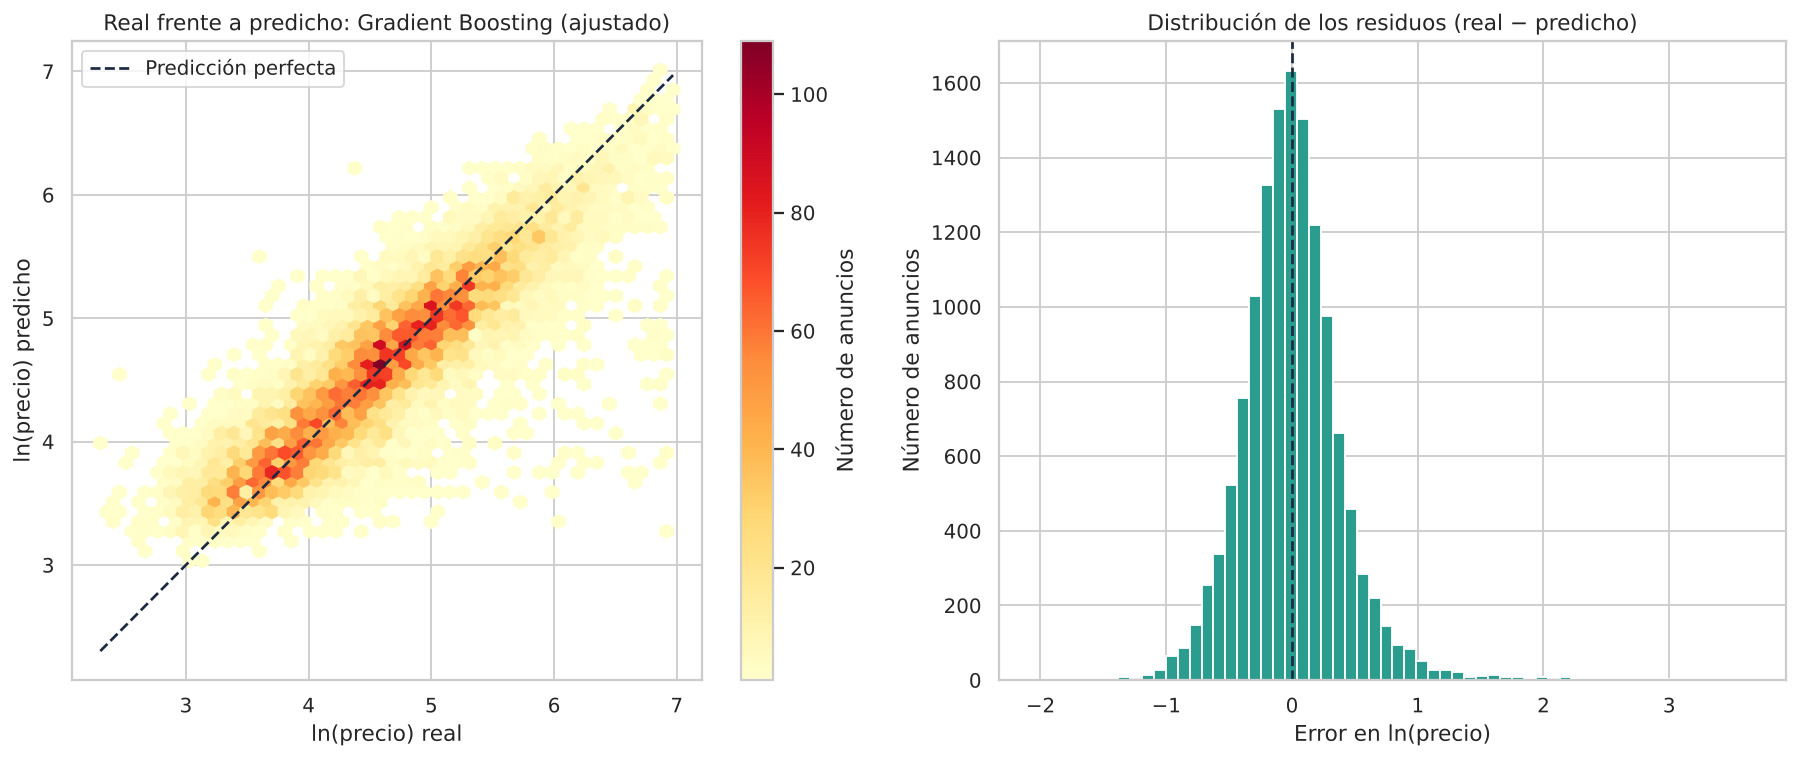

In [51]:
pred_final = pred_test[clave]
residuos = y_test - pred_final

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

hb = ax[0].hexbin(y_test, pred_final, gridsize=45, cmap='YlOrRd', mincnt=1)
lim = [y_test.min(), y_test.max()]
ax[0].plot(lim, lim, color=AZUL, linestyle='--', label='Predicción perfecta')
plt.colorbar(hb, ax=ax[0], label='Número de anuncios')
ax[0].set_title(f'Real frente a predicho: {clave}')
ax[0].set_xlabel('ln(precio) real')
ax[0].set_ylabel('ln(precio) predicho')
ax[0].legend()

ax[1].hist(residuos, bins=60, color=VERDE, edgecolor='white')
ax[1].axvline(0, color=AZUL, linestyle='--')
ax[1].set_title('Distribución de los residuos (real − predicho)')
ax[1].set_xlabel('Error en ln(precio)')
ax[1].set_ylabel('Número de anuncios')

plt.tight_layout()
plt.show()

print('Media de los residuos:', round(residuos.mean(), 4))
print('Desviación de los residuos:', round(residuos.std(), 4))
print('Anuncios con error menor al 30 % del precio:', f'{(np.abs(np.exp(pred_final) / np.exp(y_test) - 1) < 0.30).mean() * 100:.1f} %')

## **5.5 Dónde se equivoca más el modelo**

Se analiza el error por tipo de alojamiento y por rango de precio real.

                 anuncios    MAE  mediana_error_pct
room_type                                          
Entire home/apt      8148 53.200             21.400
Hotel room             40 56.500             21.500
Private room         5336 23.300             22.400
Shared room            90 33.300             43.600



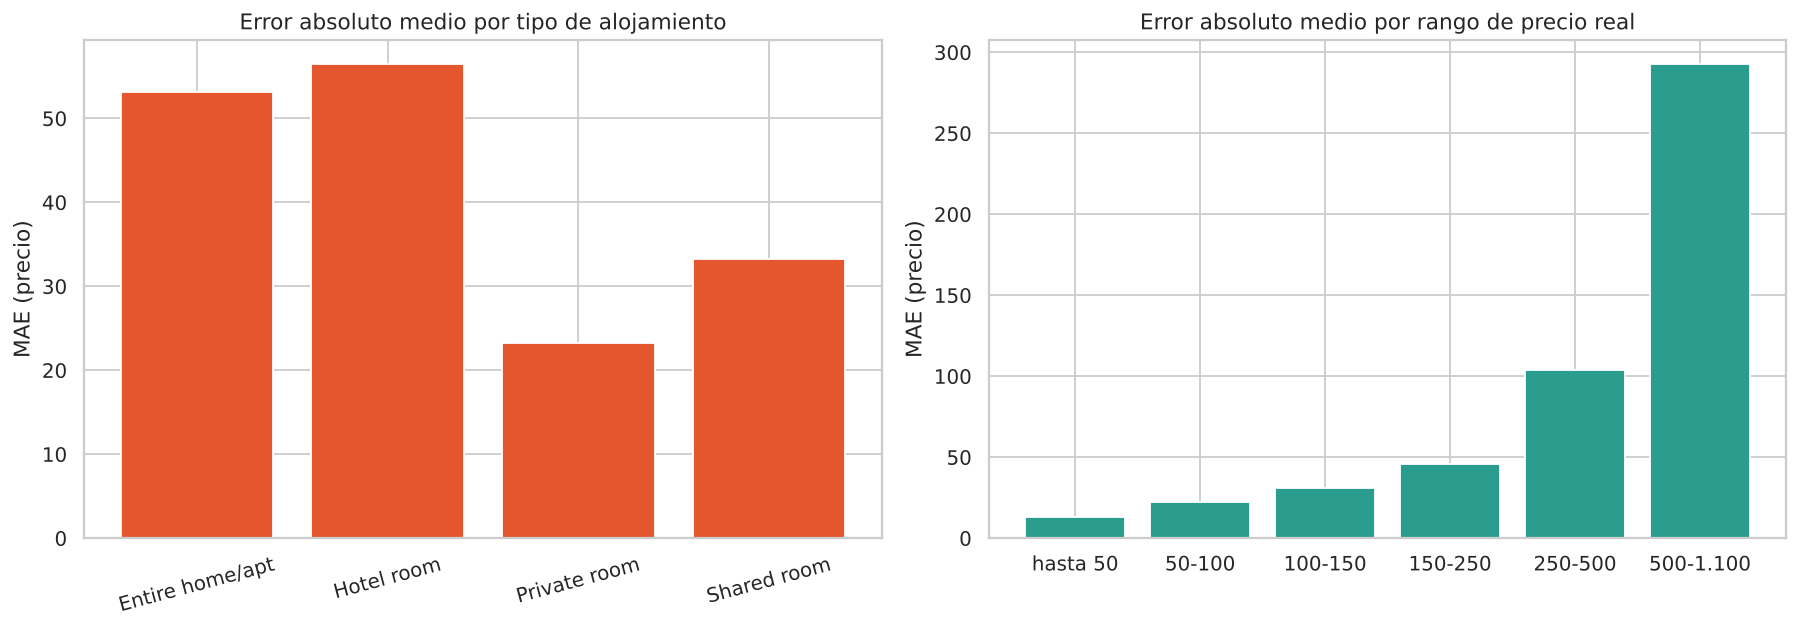

In [52]:
ev = dfp.loc[X_test.index, ['room_type', 'price_num']].copy()
ev['pred'] = np.exp(pred_final)
ev['error_abs'] = (ev['pred'] - ev['price_num']).abs()
ev['error_pct'] = ev['error_abs'] / ev['price_num'] * 100
ev['rango'] = pd.cut(ev['price_num'], [0, 50, 100, 150, 250, 500, 1100],
                     labels=['hasta 50', '50-100', '100-150', '150-250', '250-500', '500-1.100'])

por_tipo = ev.groupby('room_type').agg(anuncios=('error_abs', 'size'), MAE=('error_abs', 'mean'),
                                       mediana_error_pct=('error_pct', 'median')).round(1)
por_rango = ev.groupby('rango', observed=True).agg(anuncios=('error_abs', 'size'), MAE=('error_abs', 'mean'),
                                                   mediana_error_pct=('error_pct', 'median')).round(1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(por_tipo.index, por_tipo['MAE'], color=CORAL)
ax[0].set_title('Error absoluto medio por tipo de alojamiento')
ax[0].set_ylabel('MAE (precio)')
ax[0].tick_params(axis='x', rotation=15)
ax[1].bar(por_rango.index.astype(str), por_rango['MAE'], color=VERDE)
ax[1].set_title('Error absoluto medio por rango de precio real')
ax[1].set_ylabel('MAE (precio)')
plt.tight_layout()
plt.show()

print(por_tipo)
print()
print(por_rango)

## **5.6 Variables más importantes**

Se usa la importancia por permutación: se mezclan al azar los valores de una variable y se mide cuánto empeora el error. Cuanto más empeora, más importante es la variable.

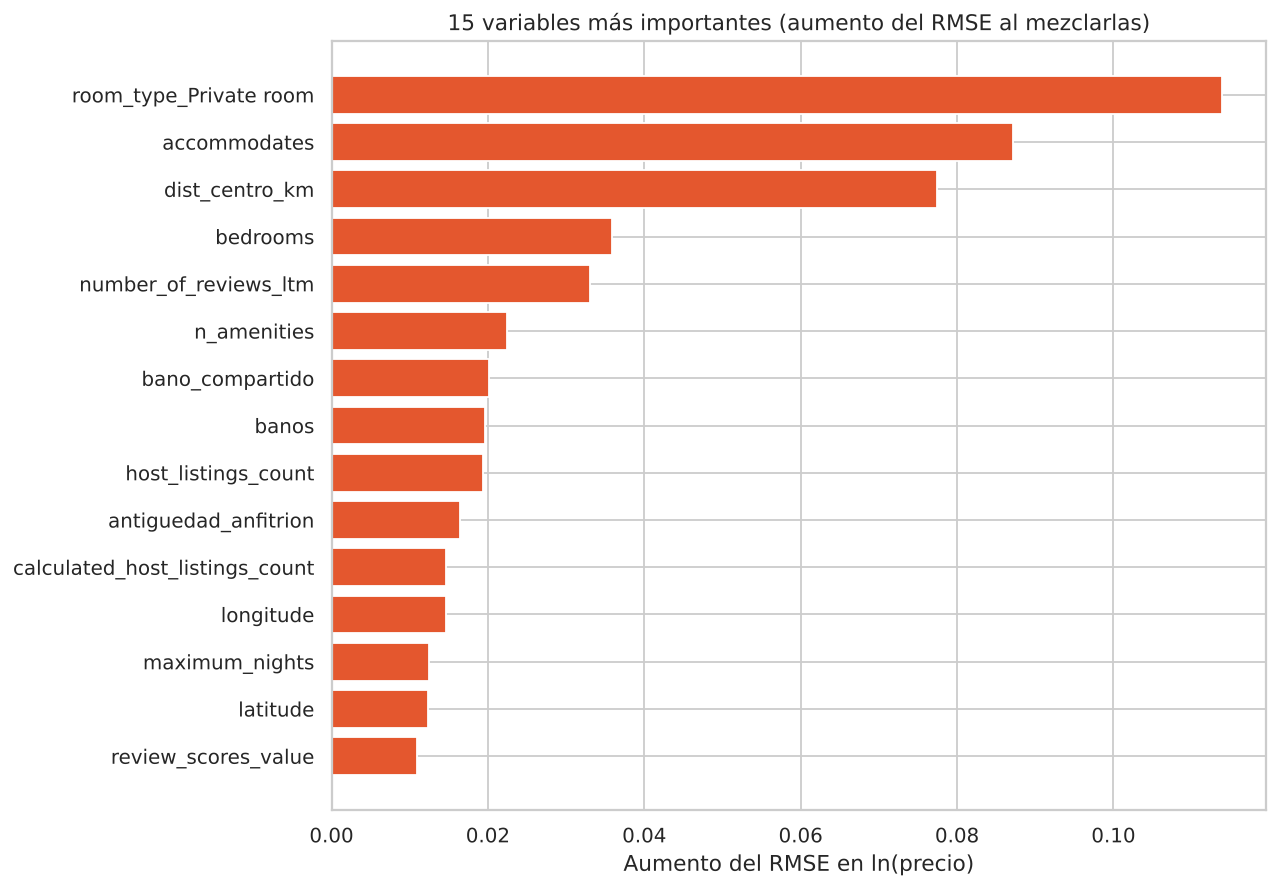

room_type_Private room   0.114
accommodates             0.087
dist_centro_km           0.077
bedrooms                 0.036
number_of_reviews_ltm    0.033
n_amenities              0.022
bano_compartido          0.020
banos                    0.020
host_listings_count      0.019
antiguedad_anfitrion     0.016

In [53]:
from sklearn.inspection import permutation_importance

modelo_final, tipo_final = entrenados[clave]
T = X_test_esc if tipo_final == 'esc' else X_test
muestra_t = T.sample(4000, random_state=42)

imp = permutation_importance(modelo_final, muestra_t, y_test.loc[muestra_t.index], n_repeats=5,
                             random_state=42, scoring='neg_root_mean_squared_error')
importancia = pd.Series(imp.importances_mean, index=T.columns).sort_values(ascending=False)

top = importancia.head(15).sort_values()
plt.figure(figsize=(10, 7))
plt.barh(top.index, top.values, color=CORAL)
plt.title('15 variables más importantes (aumento del RMSE al mezclarlas)')
plt.xlabel('Aumento del RMSE en ln(precio)')
plt.tight_layout()
plt.show()

importancia.head(10).round(3)

## **5.7 Resumen de la evaluación**

In [54]:
resumen_final = tabla_test[['R² (ln)', 'MAE (ln)', 'RMSE (ln)', 'MAE (precio)', 'RMSE (precio)']].round(3)
resumen_final['Mejora del MAE vs base (%)'] = ((base['MAE (precio)'] - tabla_test['MAE (precio)']) / base['MAE (precio)'] * 100).round(1)
resumen_final

,R² (ln),MAE (ln),RMSE (ln),MAE (precio),RMSE (precio),Mejora del MAE vs base (%)
Modelo,,,,,,
Modelo base (mediana),-0.000,0.654,0.808,84.651,144.997,0.000
Regresión lineal (Ridge),0.649,0.359,0.479,52.048,101.040,38.500
Random Forest (por defecto),0.739,0.297,0.412,41.961,84.063,50.400
Random Forest (ajustado),0.747,0.294,0.406,41.703,84.310,50.700
Gradient Boosting (por defecto),0.739,0.302,0.413,43.390,86.145,48.700
Gradient Boosting (ajustado),0.754,0.290,0.400,41.381,82.474,51.100


## **5.8 Hallazgos de la Fase 5**

*Los valores exactos pueden variar levemente según la versión de scikit-learn; las conclusiones se mantienen.*

**Modelo final.** El modelo seleccionado, Gradient Boosting con los parámetros ajustados, alcanza en el conjunto de prueba un R² cercano a 0,75 sobre ln(precio) y un error absoluto medio de unos 41 a 42 en precio, frente a cerca de 85 del modelo base: el error se reduce aproximadamente a la mitad.

**Criterios de éxito.** Se cumplen los dos criterios definidos en la Fase 1: el R² supera la meta de 0,60 y el MAE baja más de un 50 % frente al modelo base, con una meta de 25 %.

**Antes y después del ajuste.** En la prueba, el ajuste mejora el RMSE entre un 1,5 % y un 3 % y el MAE en precio hasta un 5 %; son ganancias pequeñas pero consistentes con las de la validación, y los R² de validación y de prueba son casi iguales (no hay señal de sobreajuste).

**Comparación de modelos.** La regresión lineal reduce el MAE alrededor de un 38 % frente al modelo base; los modelos de árboles lo reducen cerca del 50 %.

**Calidad de las predicciones.** La mayoría de los anuncios se predice con un error menor al 30 % del precio y los residuos están centrados en 0: el modelo no tiene un sesgo sistemático.

**Dónde se equivoca más.** El error crece con el precio: el MAE es de unos 13 en los anuncios de hasta 50 y de casi 300 entre 500 y 1.100, donde además el modelo tiende a subestimar. Por tipo de alojamiento el MAE es mayor en casas completas que en habitaciones privadas; las habitaciones compartidas y de hotel tienen pocos anuncios en la prueba (90 y 40), por lo que su resultado es menos confiable.

**Variables más importantes.** Según la importancia por permutación: el tipo habitación privada, la capacidad, la distancia al centro, el número de habitaciones y las reseñas de los últimos 12 meses. La distancia al centro y el número de comodidades, creadas en la Fase 3, están entre las más importantes. Que las reseñas recientes influyan no implica una causa: pueden reflejar la actividad o la demanda del anuncio.

**Limitaciones.** El precio es el publicado y de un solo mes; faltan variables como el estado del alojamiento o las fotos; y el modelo no se entrenó con precios mayores de 1.065 por noche, por lo que no debe usarse para alojamientos de lujo extremo.

# **FASE 6: DESPLIEGUE** *(opcional)*

Pendiente: estimador interactivo de precios, plan de mantenimiento del modelo y conclusiones del informe final.